# Table of Contents : Ocean Analysis

### Why this notebook matters

This notebook demonstrates global SST trend detection in a storm-resolving climate projection, contrasting early and late 5-year periods and quantifying the global-mean warming signal.

**Purpose** - Compute and map global sea-surface temperature (SST) trends in a 2020-2039 storm-resolving coupled projection, comparing the 2020-2024 and 2035-2039 periods and evaluating the global-mean warming signal.

**Required input data** - SST (`tos` or `avg_tos`) NetCDF files on the HEALPix grid under `{PROJ2559_DIR}` (originally on DKRZ Levante; not included in this repository).

**Expected outputs** - NetCDF trend files and global SST trend maps.

## Key techniques demonstrated

- xesmf regridding
- Dask-backed scalable processing
- seaborn statistical plotting
- tqdm progress tracking for batch processing
- Global SST trend mapping with Cartopy/cmocean

In [ ]:
# --- Data location placeholders ---------------------------------------------
# The original analysis ran on DKRZ Levante. Input data are NOT included in
# this repository. Set this path to your own data copy before running:
#
# PROJ2559_DIR : root of the projection experiment (2020-2039)

PROJ2559_DIR = "/path/to/proj2559"  # <-- EDIT before running

## Installation & loading packages

In [ ]:
import os
import numpy as np
import xarray as xr
import healpy as hp
import eccodes
import cmocean as cmo
import matplotlib.cm as cm
import matplotlib.pylab as plt

import dask.array as da


# Ocean 3D data

### Extract SST data

In [ ]:
import os
import xarray as xr
import dask.array as da
from dask.distributed import Client


# Initialize Dask client with 50GB memory
client = Client(n_workers=4, memory_limit='12.5GB', threads_per_worker=1)  # 4 workers ÃƒÆ’Ã†â€™ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Â 12.5GB = 50GB total
print(client)  # Verify allocation

In [ ]:
# Path configuration
base_input_path = f"{PROJ2559_DIR}/ocean3d_dy/tco2559_proj/0001_o3d_avg_thetao_healpix_yearly_{year:04d}.grb"
output_dir = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/"
#os.makedirs(output_dir, exist_ok=True)

In [ ]:
### Extraction of SST data

for year in range(2020, 2040):
    try:
        input_path = base_input_path.format(year=year)
        print(f"\nProcessing year {year}: {input_path}")

        # Load the GRIB file (ensure 'avg_thetao' is selected)
        ds = xr.open_dataset(
            input_path,
            engine='cfgrib',
            backend_kwargs={
                'filter_by_keys': {'typeOfLevel': 'oceanModelLayer'},
                'indexpath': ''
            }
        )

        # Extract SST (first layer) and include coordinates
        sst = ds['avg_thetao'].isel(oceanModelLayer=0).compute()  # Ensure data is loaded
        sst_ds = sst.to_dataset(name='sst')  # Convert to Dataset for proper NetCDF export

        # Preserve coordinates (latitude, longitude)
        sst_ds['latitude'] = ds['latitude']
        sst_ds['longitude'] = ds['longitude']

        # Configure encoding
        encoding = {
            'sst': {
                'zlib': True,
                'complevel': 5,
                '_FillValue': -9999.0,
            },
            'latitude': {'_FillValue': None},
            'longitude': {'_FillValue': None},
        }

        # Save to NetCDF
        output_path = os.path.join(output_dir, f"sst_{year}.nc")
        sst_ds.to_netcdf(output_path, encoding=encoding)
        print(f"ÃƒÆ’Ã‚Â¢Ãƒâ€¦Ã¢â‚¬Å“ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â¦ Saved: {output_path}")

    except Exception as e:
        print(f"ÃƒÆ’Ã‚Â¢Ãƒâ€šÃ‚ÂÃƒâ€¦Ã¢â‚¬â„¢ Failed {year}: {str(e)}")

#### Plot: sst for any year

In [ ]:
import xarray as xr
ds = xr.open_dataset(f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_2035.nc")
print(ds)

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Load the NetCDF file
file_path = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_2035.nc"
ds = xr.open_dataset(file_path)

# Extract the first timestep
sst_first = ds['sst'].isel(time=0).values  # Shape: (196608,)
lats = ds['latitude'].values               # Shape: (196608,)
lons = ds['longitude'].values              # Shape: (196608,)

# Create a figure with Cartopy projection
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

# Plot SST data (scatter plot for unstructured grid)
sc = ax.scatter(
    lons, lats, c=sst_first, 
    cmap='jet', s=1,  # Adjust point size (`s`) if needed
    transform=ccrs.PlateCarree()
)

# Add map features
ax.add_feature(cfeature.LAND, color='lightgray')
ax.add_feature(cfeature.COASTLINE)
ax.gridlines(draw_labels=True)

# Add colorbar
plt.colorbar(sc, label='Sea Surface Temperature (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¾Ãƒâ€ Ã¢â‚¬â„¢)', extend='both')

# Title
plt.title(f'SST (HEALPix Grid) - {ds.time[0].values}')

plt.show()

#### Robinson plot

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo
import healpy as hp  # Required for HEALPix interpolation

# Load the NetCDF file
file_path = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_2035.nc"
ds = xr.open_dataset(file_path)

# Extract first timestep and coordinates
sst_first = ds['sst'].isel(time=0).values  # Shape: (196608,)
lats = ds['latitude'].values               # Shape: (196608,)
lons = ds['longitude'].values              # Shape: (196608,)

# Replace NaN values (if any)
sst_first = np.nan_to_num(sst_first, nan=0.0)

# --- Step 1: Interpolate HEALPix data to regular grid ---
# Create target grid (360x180 for 1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° resolution)
grid_lon, grid_lat = np.meshgrid(
    np.linspace(-180, 180, 360),
    np.linspace(-90, 90, 180)
)
grid_sst = np.zeros_like(grid_lat)

# Interpolate using healpy (ensure `nest=True` if your data is nested HEALPix)
for i in range(grid_lon.shape[0]):
    for j in range(grid_lon.shape[1]):
        grid_sst[i, j] = hp.get_interp_val(
            sst_first, 
            grid_lon[i, j], 
            grid_lat[i, j], 
            lonlat=True, 
            nest=True  # Set to False if not nested
        )

# --- Step 2: Plot in Robinson projection ---
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Customize SST levels (adjust based on your data range)
levels = np.linspace(np.nanmin(grid_sst), np.nanmax(grid_sst), 21)

# Plot interpolated data
plot = ax.contourf(
    grid_lon, 
    grid_lat, 
    grid_sst,
    transform=ccrs.PlateCarree(),
    cmap=cmo.thermal,  # SST-optimized colormap
    levels=levels,
    extend='both'
)

# Add map features
ax.add_feature(cfeature.LAND, color='lightgray', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=3)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# Colorbar (horizontal)
cbar = plt.colorbar(
    plot, 
    orientation='horizontal', 
    pad=0.05, 
    aspect=50,
    label='Sea Surface Temperature (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¾Ãƒâ€ Ã¢â‚¬â„¢)'
)

# Title
plt.title(f'SST - {ds.time[0].values}', fontsize=14, pad=20)

plt.show()

In [ ]:
print(f"Interpolated SST min/max: {np.nanmin(grid_sst):.2f}, {np.nanmax(grid_sst):.2f}")

print(f"Original HEALPix min/max: {np.nanmin(sst_first):.2f}, {np.nanmax(sst_first):.2f}")

### Mean Calculation

In [ ]:
### Calaculate yearly mean from the daily SST data files (nc). 

# Imp: ÃƒÆ’Ã‚Â¢Ãƒâ€šÃ‚ÂÃƒâ€¦Ã¢â‚¬â„¢Don't perform this unless required

# Configuration
input_dir = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/"
output_dir = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/"
#os.makedirs(output_dir, exist_ok=True)

for year in range(2020, 2040):
    try:
        # Load daily data
        input_path = os.path.join(input_dir, f"sst_{year}.nc")
        ds = xr.open_dataset(input_path)

        # Compute yearly mean
        yearly_mean = ds['sst'].mean(dim='time', skipna=True)
        yearly_mean_ds = yearly_mean.to_dataset(name='sst')
        yearly_mean_ds.attrs = {
            'title': f'Yearly Mean SST ({year})',
            'source': f'Daily SST from {year}'
        }

        # Save
        output_path = os.path.join(output_dir, f"sst_yearly_mean_{year}.nc")
        yearly_mean_ds.to_netcdf(
            output_path,
            encoding={'sst': {'zlib': True, 'complevel': 5}}
        )
        print(f"Processed {year} ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â€žÂ¢ {output_path}")

    except Exception as e:
        print(f"Error processing {year}: {str(e)}")

In [ ]:
### Check files in the directory

import os

# Directory path
dir_path = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/"

# List all files in the directory
files = sorted(os.listdir(dir_path))

# Filter for NetCDF files (optional)
nc_files = [f for f in files if f.endswith('.nc')]

# Print results
print(f"Found {len(nc_files)} files in {dir_path}:")
for file in nc_files:
    print(f"  ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â€žÂ¢ {file}")

#### 2020-24 & 2035-39

In [ ]:
### 5 year mean calculation : Create NC files 

### a) 2020-2024 b) 2035-2039

# Configuration
input_dir = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/"
output_dir = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/"

def compute_5year_mean(start_year, end_year, period_name):
    """Compute and save 5-year mean for a given period"""
    files = [f"{input_dir}/sst_{year}.nc" for year in range(start_year, end_year+1)]
    
    # Open all files and concatenate along time dimension
    ds = xr.open_mfdataset(files, combine='by_coords')
    
    # Compute mean over time (5 years)
    mean_5year = ds['sst'].mean(dim='time', skipna=True)
    
    # Convert to dataset and add metadata
    mean_ds = mean_5year.to_dataset(name='sst')
    mean_ds.attrs = {
        'description': f'{end_year-start_year+1}-year mean SST ({start_year}-{end_year})',
        'period': period_name
    }
    
    # Save with compression
    output_path = f"{output_dir}/sst_5year_mean_{period_name}.nc"
    mean_ds.to_netcdf(
        output_path,
        encoding={'sst': {'zlib': True, 'complevel': 5}}
    )
    print(f"Saved {period_name} ({start_year}-{end_year}) to: {output_path}")

# Compute for both periods
compute_5year_mean(2020, 2024, "period1_2020-2024")
compute_5year_mean(2035, 2039, "period2_2035-2039")

In [ ]:
# Load the nc files and plot them 

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo
import healpy as hp

# Load the 5-year mean files
period1 = xr.open_dataset(f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_5year_mean_period1_2020-2024.nc")
period2 = xr.open_dataset(f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_5year_mean_period2_2035-2039.nc")

# Create target grid (360x180 for 1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° resolution)
grid_lon, grid_lat = np.meshgrid(
    np.linspace(-180, 180, 360),
    np.linspace(-90, 90, 180)
)

def prepare_data(ds):
    """Interpolate HEALPix data to regular grid"""
    sst_data = ds['sst'].values
    lats = ds['latitude'].values
    lons = ds['longitude'].values
    grid_data = np.zeros_like(grid_lat)
    
    for i in range(grid_lon.shape[0]):
        for j in range(grid_lon.shape[1]):
            grid_data[i,j] = hp.get_interp_val(
                sst_data, 
                grid_lon[i,j], 
                grid_lat[i,j], 
                lonlat=True, 
                nest=True
            )
    return grid_data

# Interpolate both periods
data1 = prepare_data(period1)
data2 = prepare_data(period2)

# Find common scale for both plots
vmin = min(np.nanmin(data1), np.nanmin(data2))
vmax = max(np.nanmax(data1), np.nanmax(data2))
levels = np.linspace(vmin, vmax, 21)

print(vmin,vmax)

In [ ]:
period1

In [ ]:
# Create figure with two subplots
fig = plt.figure(figsize=(20, 10))  # Increased height to accommodate colorbar
proj = ccrs.Robinson()

# Create grid layout with space for colorbar
gs = fig.add_gridspec(2, 2, height_ratios=[20, 1], width_ratios=[1, 1])  # 2x2 grid

# First subplot (2020-2024)
ax1 = fig.add_subplot(gs[0, 0], projection=proj)  # Top-left
plot1 = ax1.contourf(
    grid_lon, grid_lat, data1,
    transform=ccrs.PlateCarree(),
    cmap=cmo.thermal,
    levels=levels,
    extend='both'
)
ax1.add_feature(cfeature.LAND, color='lightgray')
ax1.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax1.set_title('5-Year Mean SST (2020-2024)', fontsize=16, pad=20)

# Second subplot (2035-2039)
ax2 = fig.add_subplot(gs[0, 1], projection=proj)  # Top-right
plot2 = ax2.contourf(
    grid_lon, grid_lat, data2,
    transform=ccrs.PlateCarree(),
    cmap=cmo.thermal,
    levels=levels,
    extend='both'
)
ax2.add_feature(cfeature.LAND, color='lightgray')
ax2.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax2.set_title('5-Year Mean SST (2035-2039)', fontsize=16, pad=20)

# Add common colorbar in its own subplot (spanning both columns)
cbar_ax = fig.add_subplot(gs[1, :])  # Bottom row
cbar = fig.colorbar(
    plot2, 
    cax=cbar_ax,
    orientation='horizontal',
    label='Sea Surface Temperature (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¾Ãƒâ€ Ã¢â‚¬â„¢)',
    extend='both',
    aspect=40  # Controls width-to-height ratio
)

plt.tight_layout()
plt.show()

#### 2035-39 minus 2020-24

In [ ]:
### Calculate the difference (2035-2039 minus 2020-2024)

diff_data = data2 - data1  # 2035-2039 minus 2020-2024

print(diff_data.shape)

In [ ]:
# Plot the difference

fig_diff = plt.figure(figsize=(15, 8))
ax_diff = plt.axes(projection=ccrs.Robinson())

# Auto-determine symmetric limits
abs_max = np.nanmax(np.abs(diff_data))
levels_diff = np.linspace(-abs_max, abs_max, 21)

plot_diff = ax_diff.contourf(
    grid_lon, grid_lat, diff_data,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=levels_diff,
    extend='both'
)

ax_diff.add_feature(cfeature.LAND, color='lightgray')
ax_diff.add_feature(cfeature.COASTLINE, linewidth=0.5)

cbar_diff = plt.colorbar(
    plot_diff,
    orientation='horizontal',
    label='SST Change (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã…Â¾Ãƒâ€ Ã¢â‚¬â„¢)',
    pad=0.05
)
ax_diff.set_title('SST Change (2035-2039 minus 2020-2024)', pad=20)

#### Trend

##### Calculation

In [ ]:
import xarray as xr
import numpy as np
import os
from scipy.stats import linregress

# Imp: ÃƒÆ’Ã‚Â¢Ãƒâ€šÃ‚ÂÃƒâ€¦Ã¢â‚¬â„¢Don't perform this unless required

# 1. Check files exist and are readable
yearly_files = []
for year in range(2020, 2040):
    fpath = ff"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_yearly_mean_{year}.nc"
    if os.path.exists(fpath):
        try:
            with xr.open_dataset(fpath) as ds:
                if 'sst' in ds:
                    yearly_files.append(fpath)
                    print(f"ÃƒÆ’Ã‚Â¢Ãƒâ€¦Ã¢â‚¬Å“ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ {year} loaded")
                else:
                    print(f"ÃƒÆ’Ã†â€™ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Â {year} missing 'sst' variable")
        except:
            print(f"ÃƒÆ’Ã†â€™ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Â {year} corrupted")
    else:
        print(f"ÃƒÆ’Ã†â€™ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Â {year} missing")

if not yearly_files:
    raise ValueError("No valid files found")

# 2. Load with explicit time coordination
annual_means = xr.open_mfdataset(
    yearly_files,
    combine='nested',
    concat_dim='time',
    coords='minimal',
    compat='override'
)['sst']

# 3. Ensure time dimension exists
if 'time' not in annual_means.dims:
    # Manually add time coordinate if missing
    annual_means['time'] = np.arange(2020, 2020 + len(yearly_files))
    annual_means = annual_means.set_index(time='time')

In [ ]:
print(ds)

In [ ]:
### Compute Trend

# 1. Convert to numpy array with proper shape
sst_data = annual_means.transpose('time', 'values').values

# 2. Initialize trend array
trend_values = np.full(sst_data.shape[1], np.nan)

# 3. Calculate trend per grid point
for i in range(sst_data.shape[1]):
    y = sst_data[:, i]
    valid = ~np.isnan(y)
    
    if np.sum(valid) >= 2:  # Minimum 2 points for regression
        x = np.arange(len(y))[valid]
        slope, _, _, _, _ = linregress(x, y[valid])
        trend_values[i] = slope

# 4. Create output DataArray
trend_map = xr.DataArray(
    trend_values,
    dims=["values"],
    coords={"values": annual_means["values"]},
    attrs={
        "units": "ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year",
        "period": "2020-2039",
        "calculation": "Linear least-squares trend"
    }
)

In [ ]:
output_path = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_trend_2020_2039.nc"
trend_map.to_dataset(name="sst_trend").to_netcdf(
    output_path,
    encoding={'sst_trend': {'zlib': True, 'complevel': 5}}
)

# Verify output
with xr.open_dataset(output_path) as ds:
    print("Saved file contains:")
    print(ds)
    print(f"Global mean trend: {ds['sst_trend'].mean().values:.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year")

##### Plot

In [ ]:
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Load SST trend data
sst_trend_path = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_trend_2020_2039.nc"
sst_trend = xr.open_dataset(sst_trend_path)['sst_trend']

# Print dataset info
print("SST Trend Data Structure:")
print(sst_trend)

# Check basic statistics
print("\nSST Trend Statistics:")
print(f"Global mean: {sst_trend.mean().values:.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year")
print(f"Minimum: {sst_trend.min().values:.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year")
print(f"Maximum: {sst_trend.max().values:.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year")

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import healpy as hp


# No multiplication needed since trend_map is already in ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year
trend_data = sst_trend.values.copy()  # Creates a copy to preserve original

# Mask insignificant trends (optional)
# trend_data[np.abs(trend_data) < 0.01] = np.nan  # Threshold of 0.01ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year

# Interpolate to Regular Grid
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                     np.linspace(-90, 90, 180))
grid_trend = np.zeros_like(grid_lat)

for i,j in np.ndindex(grid_lon.shape):
    grid_trend[i,j] = hp.get_interp_val(
        trend_data, 
        grid_lon[i,j], 
        grid_lat[i,j],
        lonlat=True,
        nest=True
    )



In [ ]:
# Create figure with reference-style settings
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# --- Plot SST Trend ---
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,  # Your interpolated SST trend data
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",                   # Same colormap as reference
    levels=np.linspace(-0.2, 0.2, 21),  # Adjusted for typical SST trends
    extend="both"                    # Extend colors for out-of-range values
)

# --- Add Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)      # Thicker coastline
#ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)  # Country borders
ax.gridlines(color='gray', linestyle='--', alpha=0.5)  # Reference-style gridlines

# --- Add Colorbar ---
cbar = plt.colorbar(trend_plot, 
                   ax=ax,
                   orientation='horizontal',
                   pad=0.05,
                   shrink=0.8)       # Matches reference proportions
cbar.set_label("SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year)", fontsize=12)  # Specific to your variable

# --- Add Title ---
plt.title("Trend in Sea Surface Temperature (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)", 
          fontsize=14, pad=20)
plt.show()

##### Intermdeiate reolution

In [ ]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import healpy as hp

# Load SST trend data
sst_trend_path = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_trend_2020_2039.nc"
sst_trend = xr.open_dataset(sst_trend_path)['sst_trend']

# Create 0.5ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° resolution grid (720x360)
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 720), 
                                 np.linspace(-90, 90, 360))
grid_trend = np.zeros_like(grid_lat)

# Interpolate HEALPix to regular grid
trend_data = sst_trend.values.copy()
for i,j in np.ndindex(grid_lon.shape):
    grid_trend[i,j] = hp.get_interp_val(
        trend_data, 
        grid_lon[i,j], 
        grid_lat[i,j],
        lonlat=True,
        nest=True
    )


In [ ]:
# ========== Enhanced Plotting for Poster ==========
plt.rcParams.update({'font.size': 14})  # Larger font for posters

# Create figure with larger size for poster
fig = plt.figure(figsize=(20, 12), dpi=300)  # High DPI for print quality
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# --- Plot SST Trend with improved settings ---
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.2, 0.2, 21),
    extend="both"
)

# --- Enhanced Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=1.2, edgecolor='black')
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=0)
#ax.add_feature(cfeature.LAKES, facecolor='white', edgecolor='none', zorder=1)
#ax.add_feature(cfeature.RIVERS, edgecolor='lightblue', linewidth=0.5, zorder=1)

# Custom gridlines
gl = ax.gridlines(color='gray', linestyle='--', alpha=0.7, 
                 draw_labels=False, linewidth=0.8)
gl.xlines = True
gl.ylines = True

# --- Professional Colorbar ---
cbar = plt.colorbar(trend_plot, 
                   ax=ax,
                   orientation='horizontal',
                   pad=0.03,
                   shrink=0.7,
                   aspect=40,
                   extendfrac='auto',
                   ticks=np.linspace(-0.2, 0.2, 11))  # More ticks for precision

cbar.set_label("Sea Surface Temperature Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year)", 
              fontsize=16)#, weight='bold')
cbar.ax.tick_params(labelsize=18)

# --- Title and Annotation ---
plt.title("Global Sea Surface Temperature Trend (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)", 
         fontsize=34, pad=25)#, weight='bold')

# # Add data source annotation
# plt.annotate("Data: Projection | Visualization: DestinE", 
#             xy=(0.5, 0.01), xycoords='figure fraction',
#             ha='center', fontsize=12, color='gray')

# Add significance note if masking was applied
# plt.annotate("Areas with trends < 0.01ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year masked", 
#             xy=(0.5, 0.05), xycoords='figure fraction',
#             ha='center', fontsize=10, style='italic')

plt.tight_layout()  # Prevent label cutoff
plt.savefig('SST_trend_poster.png', bbox_inches='tight', dpi=300)  # Save high-res
plt.show()

#### Statistically significant SST trends

In [ ]:
import numpy as np
from scipy.stats import linregress

# Initialize arrays for results
trend_values = np.full(annual_means.shape[1], np.nan)  # Shape: (values,)
p_values = np.full(annual_means.shape[1], np.nan)      # Store p-values

# Convert to numpy array for efficient computation
sst_data = annual_means.transpose('time', 'values').values

for i in range(sst_data.shape[1]):
    y = sst_data[:, i]
    valid = ~np.isnan(y)
    
    if np.sum(valid) >= 5:  # Minimum 5 years for significance testing
        x = np.arange(len(y))[valid]
        slope, _, r_value, p_value, _ = linregress(x, y[valid])
        
        # Store results
        p_values[i] = p_value
        if p_value < 0.05:  # Only keep significant trends
            trend_values[i] = slope

In [ ]:
# Create xarray Dataset with both trend and p-value
trend_ds = xr.Dataset({
    'trend': xr.DataArray(
        trend_values,
        dims=["values"],
        coords={"values": annual_means["values"]},
        attrs={"units": "ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year", "description": "Significant trends (p<0.05)"}
    ),
    'p_value': xr.DataArray(
        p_values,
        dims=["values"],
        coords={"values": annual_means["values"]},
        attrs={"description": "p-values from linear regression"}
    )
})

# Save results
output_path = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_trend_significant_2020_2039.nc"
trend_ds.to_netcdf(output_path)

In [ ]:
# Interpolate to regular grid
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                     np.linspace(-90, 90, 180))
grid_trend = np.zeros_like(grid_lat)
grid_sig = np.zeros_like(grid_lat)  # For significance mask

for i,j in np.ndindex(grid_lon.shape):
    grid_trend[i,j] = hp.get_interp_val(trend_ds['trend'].values, 
                                       grid_lon[i,j], grid_lat[i,j],
                                       lonlat=True, nest=True)
    grid_sig[i,j] = hp.get_interp_val((p_values < 0.05).astype(float),
                                       grid_lon[i,j], grid_lat[i,j],
                                       lonlat=True, nest=True)

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Create figure with reference-style settings
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# --- Plot Settings ---
levels = np.linspace(-0.2, 0.2, 21)  # Consistent with SST range
cmap = "RdBu_r"  # Matching reference colormap

# --- Plot All Trends (Transparent Base Layer) ---
base = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    levels=levels,
    extend="both",
    alpha=0.2  # Semi-transparent
)

# --- Plot Significant Trends (Opaque) ---
sig = ax.contourf(
    grid_lon, grid_lat, 
    np.where(grid_sig > 0.5, grid_trend, np.nan),  # Mask non-significant
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    levels=levels,
    extend="both"
)

# --- Significance Stippling ---
ax.contourf(
    grid_lon, grid_lat, grid_sig,
    levels=[0.5, 1.5],
    colors='none',
    hatches=['.....'],  # Finer stippling
    transform=ccrs.PlateCarree()
)

# --- Map Features ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.add_feature(cfeature.LAND, color='lightgray')
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Colorbar ---
cbar = plt.colorbar(
    sig,
    ax=ax,
    orientation='horizontal',
    pad=0.05,
    shrink=0.8
)
cbar.set_label("SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year) (p < 0.05)", fontsize=12)

# --- Title ---
plt.title("Statistically Significant Sea Surface Temperature Trends (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)\n"
          "Stippling indicates p-value < 0.05", 
          fontsize=14, pad=20)

plt.show()

In [ ]:
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

# Only plot significant trends
plot = ax.pcolormesh(
    grid_lon, grid_lat, np.ma.masked_where(grid_sig < 0.5, grid_trend),
    transform=ccrs.PlateCarree(),
    cmap='coolwarm',
    vmin=-0.05, vmax=0.05
)

ax.add_feature(cfeature.LAND, color='lightgray')
ax.add_feature(cfeature.COASTLINE)
plt.colorbar(plot, label='Significant SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year) (p < 0.05)')
plt.title('Statistically Significant SST Trends Only (2020-2039)')
plt.show()

### Marine Heat waves

In [ ]:
import xarray as xr
import numpy as np
import warnings

# Load the 5-year mean files

# Baseline Period (2020-2024): Used to define "normal" SST conditions
period1 = xr.open_dataset(f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_5year_mean_period1_2020-2024.nc")
# Future Period (2035-2039): Assessed against this baseline
period2 = xr.open_dataset(f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_5year_mean_period2_2035-2039.nc")


In [ ]:
from dask.distributed import Client
client = Client(n_workers=4, memory_limit='12.5GB')  # 4 workers ÃƒÆ’Ã†â€™ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Â 12.5GB = 50GB

In [ ]:
# Load the baseline data from where we can calculate threshold

# Load 2020-2024 daily data with time in single chunks
baseline_daily = xr.open_mfdataset(
    [ff"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_{year}.nc" for year in range(2020, 2025)],
    combine='by_coords',
    chunks={'time': -1, 'values': 10000},  # Single time chunk, spatial chunks
    parallel=True
)

print(baseline_daily)

In [ ]:
# data processing and threshold calcuclation

# 1. Load and chunk data
sst_daily = baseline_daily['sst'].chunk({'time': -1})

# 2. Filter NaN regions
sst_valid = sst_daily.where(sst_daily.count(dim='time') > 0)

# 3. Calculate threshold with NaN handling
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', 'All-NaN slice encountered')
    threshold = sst_valid.quantile(
        q=0.95,
        dim='time',
        skipna=True
    ).compute()

# 4. Validate
print(f"Threshold valid at {threshold.notnull().sum().values} grid points")
print(f"Max threshold: {threshold.max().values:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")

In [ ]:
print(threshold)

In [ ]:
# MHW Counts from 2035 to2039 & avg. annual freq. 

mhw_counts = []
for year in range(2035, 2040):
    daily_ds = xr.open_dataset(
        ff"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_{year}.nc",
        chunks={'time': 30, 'values': 10000}  # Process in monthly chunks
    )
    counts = (daily_ds['sst'] > threshold).sum(dim='time').compute()
    mhw_counts.append(counts)
    
total_mhw_days = sum(mhw_counts)
mhw_freq = total_mhw_days / 5  # Average annual frequency

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig = plt.figure(figsize=(12,6))
ax = plt.axes(projection=ccrs.Robinson())

# Create grid for HEALPix data (same as before)
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                     np.linspace(-90, 90, 180))
grid_mhw = np.zeros_like(grid_lat)

# Interpolate HEALPix to regular grid
for i in range(grid_lon.shape[0]):
    for j in range(grid_lon.shape[1]):
        grid_mhw[i,j] = hp.get_interp_val(
            mhw_freq.values, 
            grid_lon[i,j], 
            grid_lat[i,j], 
            lonlat=True, 
            nest=True
        )

# Plot using pcolormesh
mesh = ax.pcolormesh(
    grid_lon, grid_lat, grid_mhw,
    transform=ccrs.PlateCarree(),
    cmap='hot_r',
    vmin=0,
    vmax=200  # Adjust based on your data range
)

# Add map features
ax.add_feature(cfeature.LAND, color='lightgray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add colorbar
cbar = plt.colorbar(
    mesh, 
    orientation='horizontal',
    pad=0.05,
    label='MHW Days/Year'
)

ax.set_title('Marine Heatwave Frequency (2035-2039 vs 2020-2024 Threshold)')
plt.show()

In [ ]:
print(mhw_freq.min)

In [ ]:
# Print threshold stats
print("Threshold Statistics (95th percentile of 2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2024 SST):")
print(f"- Valid grid points: {threshold.notnull().sum().values}")
print(f"- Max threshold: {threshold.max().values:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")
print(f"- Min threshold: {threshold.min().values:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")
print(f"- Global mean: {threshold.mean().values:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")

In [ ]:
# Print MHW frequency stats
print("\nMHW Frequency Stats (2035ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039 Avg Days/Year):")
print(f"- Max MHW days/year: {mhw_freq.max().values:.1f}")
print(f"- Min MHW days/year: {mhw_freq.min().values:.1f}")
print(f"- Global mean: {mhw_freq.mean().values:.1f}")

In [ ]:
# Print yearly MHW days (2035ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)
for i, year in enumerate(range(2035, 2040)):
    print(f"Year {year}: {mhw_counts[i].max().values:.1f} max MHW days")

#### Duration Threshold

In [ ]:
# MHWs are typically defined as events lasting ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥5 consecutive days where SST exceeds the threshold. 
# The above count includes all exceedance days regardless of duration.

In [ ]:
import xarray as xr
import numpy as np
import dask.array as da
import warnings

from dask.distributed import Client

# Initialize Dask client (automatically finds available port)
client = Client(
    n_workers=4, 
    memory_limit='12.5GB',
    threads_per_worker=1
)

print(client)
print(client.dashboard_link)

In [ ]:
# Load Baseline Daily SST Data (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2024)

baseline_daily = xr.open_mfdataset(
    [ff"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_{year}.nc" for year in range(2020, 2025)],
    combine='by_coords',
    chunks={'time': -1, 'values': 10000},
    parallel=True
)
sst_baseline = baseline_daily['sst'].chunk({'time': -1})

sst_baseline

In [ ]:
# Compute 95th Percentile Threshold from Baseline

# Filter invalid values (e.g., land points)
sst_valid = sst_baseline.where(sst_baseline.count(dim='time') > 0)

# Compute 95th percentile threshold for each grid point
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', 'All-NaN slice encountered')
    threshold = sst_valid.quantile(q=0.95, dim='time', skipna=True).compute()

threshold

In [ ]:
# Define MHW Detection Function

def detect_mhw_events(sst, threshold, min_duration=5):
    """
    Identify MHW events: SST > threshold for ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥min_duration consecutive days.
    
    Parameters:
    - sst: xarray.DataArray with shape (time, values)
    - threshold: xarray.DataArray with shape (values,)
    
    Returns:
    - mhw_days: xarray.DataArray with total number of MHW days
    """
    # Broadcast threshold to time dimension
    exceedance = sst > threshold

    def count_events_1d(arr):
        arr = np.asarray(arr)
        mhw_days = 0
        i = 0
        while i < len(arr):
            if arr[i]:
                duration = 1
                while (i + duration < len(arr)) and arr[i + duration]:
                    duration += 1
                if duration >= min_duration:
                    mhw_days += duration
                i += duration
            else:
                i += 1
        return mhw_days

    # Apply function to each spatial point in parallel
    mhw_days = xr.apply_ufunc(
        count_events_1d,
        exceedance,
        input_core_dims=[['time']],
        vectorize=True,
        dask='parallelized',
        output_dtypes=[int]
    )
    
    return mhw_days

In [ ]:
# Detect MHWs for Each Future Year and Compute Frequency

mhw_events_per_year = []

for year in range(2035, 2040):
    print(f"Processing year {year}...")
    ds = xr.open_dataset(
        ff"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_{year}.nc",
        chunks={'time': 30, 'values': 10000}
    )
    
    # Rechunk time as a single chunk for apply_ufunc compatibility
    sst = ds['sst'].chunk({'time': -1})
    
    mhw_year = detect_mhw_events(sst, threshold)
    mhw_events_per_year.append(mhw_year)

# Sum all years and compute average frequency
total_mhw_days = sum(mhw_events_per_year)
mhw_frequency = total_mhw_days / 5
mhw_frequency = mhw_frequency.compute()

mhw_frequency

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Create figure and map
fig = plt.figure(figsize=(14, 7))
ax = plt.axes(projection=ccrs.Robinson())

# Scatter plot for HEALPix-like irregular grid
sc = ax.scatter(
    mhw_frequency['longitude'].values,
    mhw_frequency['latitude'].values,
    c=mhw_frequency.values,
    s=5,  # dot size
    cmap='hot_r',
    transform=ccrs.PlateCarree(),
    vmin=0,
    vmax=200  # Adjust based on range
)

# Add map features
ax.add_feature(cfeature.LAND, color='lightgray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.3)
ax.set_global()

# Colorbar
cbar = plt.colorbar(sc, orientation='horizontal', pad=0.05)
cbar.set_label('Marine Heatwave Days/Year')

# Title
ax.set_title("Marine Heatwave Frequency (2035ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039, ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥5-Day Events, Threshold: 2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2024)")

plt.tight_layout()
plt.show()

In [ ]:
print(mhw_frequency)
print(mhw_frequency.coords)
print(mhw_frequency.shape)

In [ ]:
import numpy as np

# Create a 0.5ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° resolution grid (720x360)
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 720), 
                                 np.linspace(-90, 90, 360))
grid_mhw_frequency = np.zeros_like(grid_lat)

In [ ]:
import healpy as hp

# Assuming mhw_frequency is the array with MHW event counts (e.g., from 2035-2039)
mhw_data = mhw_frequency.values.copy()  # Convert the xarray data to numpy array

# Interpolate MHW data to regular grid
for i, j in np.ndindex(grid_lon.shape):
    grid_mhw_frequency[i, j] = hp.get_interp_val(
        mhw_data, 
        grid_lon[i, j], 
        grid_lat[i, j], 
        lonlat=True, 
        nest=True
    )

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ========== Enhanced Plotting for Poster ==========
plt.rcParams.update({'font.size': 14})  # Larger font for posters

# Create figure with larger size for poster
fig = plt.figure(figsize=(20, 12), dpi=300)  # High DPI for print quality
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))

# --- Plot MHW Frequency with improved settings ---
mhw_plot = ax.contourf(
    grid_lon, grid_lat, grid_mhw_frequency,
    transform=ccrs.PlateCarree(),
    cmap="hot_r",  # Choose a suitable colormap for frequency (e.g., 'hot_r')
    levels=np.linspace(0, 200, 21),  # Adjust levels for your data range
    extend="both"
)

# --- Enhanced Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=1.2, edgecolor='black')
ax.add_feature(cfeature.LAND, facecolor='lightgray', zorder=0)

# Custom gridlines
gl = ax.gridlines(color='gray', linestyle='--', alpha=0.7, 
                 draw_labels=False, linewidth=0.8)
gl.xlines = True
gl.ylines = True

# --- Professional Colorbar ---
cbar = plt.colorbar(mhw_plot, 
                   ax=ax,
                   orientation='horizontal',
                   pad=0.03,
                   shrink=0.7,
                   aspect=40,
                   extendfrac='auto',
                   ticks=np.linspace(0, 200, 11))  # Adjust ticks based on your data range

cbar.set_label("Marine Heatwave Days/Year", fontsize=16) #, weight='bold')
cbar.ax.tick_params(labelsize=18)

# --- Title and Annotation ---
plt.title("Marine Heatwave Frequency (2035ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ39, ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥5-Day Events, Threshold: 2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ24)", 
         fontsize=34, pad=25) #, weight='bold')

plt.tight_layout()  # Prevent label cutoff
plt.show()

#### April-May 2025

In [ ]:
# @ Levante
patho2d_tos = f"{PROJ2559_DIR}/ocean2d_dy/0001_o2d_avg_tos_healpix_daily_2025.grb"
data_o2d_tos = xr.open_dataset(patho2d_tos, engine="cfgrib")
data_o2d_tos

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo
import healpy as hp

# Load the data
patho2d_tos = f"{PROJ2559_DIR}/ocean2d_dy/0001_o2d_avg_tos_healpix_daily_2025.grb"
data_o2d_tos = xr.open_dataset(patho2d_tos, engine="cfgrib")

# Select May 19, 2025
may_19_data = data_o2d_tos.sel(time='2025-05-19')

# Extract SST, latitude, longitude (HEALPix format)
sst = may_19_data['avg_tos'].values  # Shape: (196608,)
lats = may_19_data['latitude'].values
lons = may_19_data['longitude'].values

# Replace NaN values (if any)
sst = np.nan_to_num(sst, nan=0.0)

In [ ]:
# Create target grid (adjust resolution as needed)
grid_lon, grid_lat = np.meshgrid(
    np.linspace(-180, 180, 360),  # 1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° resolution
    np.linspace(-90, 90, 180))
grid_sst = np.zeros_like(grid_lat)

# Interpolate using healpy (assumes nested HEALPix; set nest=False if not)
for i in range(grid_lon.shape[0]):
    for j in range(grid_lon.shape[1]):
        grid_sst[i, j] = hp.get_interp_val(
            sst, 
            grid_lon[i, j], 
            grid_lat[i, j], 
            lonlat=True, 
            nest=True  # Change to False if your data is ring-ordered
        )

In [ ]:
# Create figure and axis with Robinson projection
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=20))

# Set map extent to the region of interest
ax.set_extent([-20, 15, 45, 70], crs=ccrs.PlateCarree())

# Plot interpolated SST
levels = np.linspace(5, 25, 21)  # Adjust based on your SST range
plot = ax.contourf(
    grid_lon, 
    grid_lat, 
    grid_sst,
    levels=levels,
    transform=ccrs.PlateCarree(),
    cmap=cmo.balance,  # SST-optimized colormap
    extend='both'
)

# Add map features
ax.add_feature(cfeature.LAND, color='lightgray', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=3)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5, zorder=3)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# Add colorbar
cbar = plt.colorbar(
    plot, 
    orientation='horizontal', 
    pad=0.05, 
    aspect=50,
    label='Sea Surface Temperature (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)'
)

# Title
plt.title('SST on May 19, 2025 (Northeast European Shelf)', fontsize=14, pad=20)

plt.show()

In [ ]:
colormaps = [cmo.thermal, cmo.balance, 'viridis', 'plasma']
fig, axes = plt.subplots(2, 2, figsize=(15, 10), subplot_kw={'projection': ccrs.Robinson()})

for ax, cmap in zip(axes.flat, colormaps):
    plot = ax.contourf(grid_lon, grid_lat, grid_sst, levels=levels, cmap=cmap, transform=ccrs.PlateCarree())
    ax.set_title(f'Colormap: {cmap}')
    ax.coastlines()
    plt.colorbar(plot, ax=ax, orientation='horizontal')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo

# Create figure and axis with Robinson projection
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))  # Centered on 0ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°E

# Set map extent to Northwest European Shelf
ax.set_extent([-20, 15, 45, 70], crs=ccrs.PlateCarree())

# Plot interpolated SST
levels = np.linspace(5, 25, 21)
plot = ax.contourf(
    grid_lon, 
    grid_lat, 
    grid_sst,
    levels=levels,
    transform=ccrs.PlateCarree(),
    cmap=cmo.thermal,
    extend='both'
)

# --- Add map features ---
ax.add_feature(cfeature.LAND, color='lightgray', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=3)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5, zorder=3)

# --- Add latitude/longitude gridlines and labels ---
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
)
gl.top_labels = False   # Disable top labels
gl.right_labels = False # Disable right labels
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}

# --- Add colorbar ---
cbar = plt.colorbar(
    plot, 
    orientation='horizontal', 
    pad=0.05, 
    aspect=50,
    label='Sea Surface Temperature (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)'
)

# --- Title and final touches ---
plt.title('SST on May 19, 2025 (Northwest European Shelf)', fontsize=14, pad=20, weight='bold')
plt.tight_layout()
plt.show()

#### Make video May 2025

In [ ]:
# Load May Data & Define Region

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo
import healpy as hp
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Load data and subset for May 2025
path = f"{PROJ2559_DIR}/ocean2d_dy/0001_o2d_avg_tos_healpix_daily_2025.grb"
data = xr.open_dataset(path, engine="cfgrib")
may_data = data.sel(time=data['time.month'] == 5)  # May only

# Region: Northwest European Shelf
lon_bounds = [-20, 15]
lat_bounds = [45, 70]

In [ ]:
#Set Up Animation Framework

# Create target grid (1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° resolution, same as before)
grid_lon, grid_lat = np.meshgrid(
    np.linspace(lon_bounds[0], lon_bounds[1], 100),  # Adjust resolution if needed
    np.linspace(lat_bounds[0], lat_bounds[1], 100)
)

# Initialize figure
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))
ax.set_extent(lon_bounds + lat_bounds, crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, color='lightgray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

In [ ]:
# Define Interpolation Function
def interpolate_healpix(healpix_data):
    """Convert 1D HEALPix to 2D grid (same as your working example)."""
    grid_data = np.zeros_like(grid_lat)
    for i in range(grid_lon.shape[0]):
        for j in range(grid_lon.shape[1]):
            grid_data[i,j] = hp.get_interp_val(
                healpix_data,
                grid_lon[i,j], 
                grid_lat[i,j],
                lonlat=True,
                nest=True  # Assuming nested ordering (change to False if needed)
            )
    return grid_data

In [ ]:
#Animation Update Function

def update(frame):
    # Get daily data and interpolate
    day_data = may_data.isel(time=frame)
    sst_2d = interpolate_healpix(day_data['avg_tos'].values)
    
    # Clear previous frame and redraw
    ax.clear()
    ax.set_extent(lon_bounds + lat_bounds, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, color='lightgray')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    
    # Plot SST
    contour = ax.contourf(
        grid_lon, grid_lat, sst_2d,
        levels=np.linspace(5, 25, 21),
        cmap=cmo.balance,  # Using your chosen colormap
        transform=ccrs.PlateCarree()
    )
    ax.set_title(f'SST: May {frame+1}, 2025', fontsize=12)
    return contour

In [ ]:
# Generate animation (same FuncAnimation setup as before)
ani = FuncAnimation(
    fig, 
    update, 
    frames=len(may_data.time),  
    interval=200,  
    blit=False
)

# Display in Jupyter (using your working method)
plt.close()  # Prevents duplicate display
HTML(ani.to_jshtml())  # This worked for your MLD animation

In [ ]:
# === Animation Setup ===
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={'projection': ccrs.Robinson(central_longitude=0)})
ax.set_extent([-20, 15, 45, 70], crs=ccrs.PlateCarree())

# Add map features
ax.add_feature(cfeature.LAND, color='lightgray', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=3)

# === Add Latitude/Longitude Gridlines ===
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
)
gl.top_labels = False    # Disable top labels
gl.right_labels = False  # Disable right labels
gl.xlabel_style = {'size': 8}
gl.ylabel_style = {'size': 8}

# Initialize plot
contour = ax.contourf(
    grid_lon, grid_lat, 
    interpolate_healpix(may_data.isel(time=0)['avg_tos'].values),
    levels=np.linspace(5, 25, 21),
    cmap=cmo.balance,
    transform=ccrs.PlateCarree()
)
cbar = plt.colorbar(contour, orientation='horizontal', pad=0.05, aspect=50, label='SST (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)')

# === Update Function ===
def update(frame):
    ax.clear()
    ax.set_extent([-20, 15, 45, 70], crs=ccrs.PlateCarree())
    
    # Re-add features and gridlines (cleared by ax.clear())
    ax.add_feature(cfeature.LAND, color='lightgray', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=3)
    gl = ax.gridlines(
        crs=ccrs.PlateCarree(),
        draw_labels=True,
        linewidth=0.5,
        color='gray',
        alpha=0.5,
        linestyle='--'
    )
    gl.top_labels = False
    gl.right_labels = False
    
    # Update data
    sst_2d = interpolate_healpix(may_data.isel(time=frame)['avg_tos'].values)
    contour = ax.contourf(
        grid_lon, grid_lat, sst_2d,
        levels=np.linspace(5, 25, 21),
        cmap=cmo.balance,
        transform=ccrs.PlateCarree()
    )
    
    # Update title with day number
    ax.set_title(f'Northwest European Shelf - Daily SST (May {frame+1}, 2025)', 
                fontsize=12, pad=10, weight='bold')
    return contour

# === Generate Animation ===
ani = FuncAnimation(fig, update, frames=len(may_data.time), interval=200, blit=False)
plt.close()
HTML(ani.to_jshtml())

#### April-May-June

In [ ]:
# Load and Subset Data (15 April ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ 15 June)

import xarray as xr

# Load dataset (assuming 'avg_tos' is the variable of interest)
path = f"{PROJ2559_DIR}/ocean2d_dy/0001_o2d_avg_tos_healpix_daily_2025.grb"
data = xr.open_dataset(path, engine="cfgrib")

# Subset data from 15 April to 15 June 2025
subset_data = data.sel(time=slice("2025-04-15", "2025-06-15"))

In [ ]:
# Set Region and Create Target Grid

import numpy as np

# Define region: Northwest European Shelf
lon_bounds = [-15, 15]
lat_bounds = [45, 70]

# Create regular 2D grid for interpolation (e.g., 100x100 resolution)
grid_lon, grid_lat = np.meshgrid(
    np.linspace(lon_bounds[0], lon_bounds[1], 100),
    np.linspace(lat_bounds[0], lat_bounds[1], 100)
)

In [ ]:
#  Define HEALPix Interpolation Function

import healpy as hp

def interpolate_healpix(healpix_data):
    grid_data = np.zeros_like(grid_lat)
    for i in range(grid_lat.shape[0]):
        for j in range(grid_lat.shape[1]):
            grid_data[i, j] = hp.get_interp_val(
                healpix_data,
                grid_lon[i, j], grid_lat[i, j],
                lonlat=True,
                nest=True  # change to False if not nested
            )
    return grid_data

In [ ]:
# Set Up Animation Plot
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo

fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))
ax.set_extent(lon_bounds + lat_bounds, crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, color='lightgray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add gridlines with larger fonts
gl = ax.gridlines(draw_labels=True, linewidth=0.5, linestyle='--', color='gray', alpha=0.7)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 12}
gl.ylabel_style = {'size': 12}

# Initial dummy plot for colorbar setup
init_sst = interpolate_healpix(subset_data.isel(time=0)['avg_tos'].values)
img = ax.contourf(
    grid_lon, grid_lat, init_sst,
    levels=np.linspace(0, 20, 41),
    cmap=cmo.balance,
    transform=ccrs.PlateCarree()
)

# Add colorbar (static, linked to dummy image)
cbar = fig.colorbar(img, ax=ax, orientation='vertical', shrink=0.7, pad=0.05)
cbar.set_label('Sea Surface Temperature (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)', fontsize=14)
cbar.ax.tick_params(labelsize=12)

In [ ]:
def update(frame):
    day_data = subset_data.isel(time=frame)
    sst_2d = interpolate_healpix(day_data['avg_tos'].values)

    ax.clear()
    ax.set_extent(lon_bounds + lat_bounds, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, color='lightgray')
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

    # Add gridlines again (needed after clearing)
    gl = ax.gridlines(draw_labels=True, linewidth=0.5, linestyle='--', color='gray', alpha=0.7)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 14}
    gl.ylabel_style = {'size': 14}

    # Plot SST
    contour = ax.contourf(
        grid_lon, grid_lat, sst_2d,
        levels=np.linspace(0, 20, 41),
        cmap=cmo.balance,
        transform=ccrs.PlateCarree()
    )

    # Add title
    date_str = str(day_data['time'].dt.strftime('%Y-%m-%d').values)
    ax.set_title(f'Sea Surface Temperature on {date_str}', fontsize=16)

    return contour

In [ ]:
ani = FuncAnimation(
    fig,
    update,
    frames=len(subset_data.time),
    interval=200,
    blit=False
)

plt.close()  # Prevents duplicate display
HTML(ani.to_jshtml())

In [ ]:
# Save animation as GIF (with Pillow)
output_path = f"{PROJ2559_DIR}/ocean2d_dy/ana_var_sst/sst_AMJ_MHW_ani.gif"
ani.save(output_path, writer='pillow', fps=2)

plt.close()

In [ ]:
# Create figure and axes
fig = plt.figure(figsize=(12, 8))
main_ax = plt.axes(projection=ccrs.Robinson(central_longitude=0))
main_ax.set_extent(lon_bounds + lat_bounds, crs=ccrs.PlateCarree())
main_ax.add_feature(cfeature.LAND, color='lightgray')
main_ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add a colorbar axis
cbar_ax = fig.add_axes([0.25, 0.08, 0.5, 0.02])  # [left, bottom, width, height]

# Initial data (first day)
init_sst = interpolate_healpix(subset_data.isel(time=0)['avg_tos'].values)

# Plot placeholder with imshow
img = main_ax.imshow(
    init_sst,
    extent=[lon_bounds[0], lon_bounds[1], lat_bounds[0], lat_bounds[1]],
    origin='lower',
    cmap=plt.cm.hot_r,
    vmin=5, vmax=15,
    transform=ccrs.PlateCarree()
)

# Colorbar
cbar = fig.colorbar(img, cax=cbar_ax, orientation='horizontal')
cbar.set_label('SST (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)')

# Title
title = main_ax.set_title("Sea Surface Temperature")

In [ ]:
def update(frame):
    sst_2d = interpolate_healpix(subset_data.isel(time=frame)['avg_tos'].values)
    img.set_data(sst_2d)

    # Update title with date
    date_str = str(subset_data['time'].isel(time=frame).dt.strftime('%Y-%m-%d').values)
    title.set_text(f"Sea Surface Temperature\n{date_str}")
    return [img, title]

In [ ]:
ani = FuncAnimation(
    fig,
    update,
    frames=len(subset_data.time),
    interval=200,
    blit=False
)

plt.close()
HTML(ani.to_jshtml())

### ENSO 

#### Check data and plot

In [ ]:
import xarray as xr
import numpy as np
import warnings

# Load the 5-year mean files

# Baseline Period (2020-2024): Used to define "normal" SST conditions
data_sst = xr.open_dataset(f"{PROJ2559_DIR}/ocean2d_dy/0001_o2d_avg_tos_healpix_daily_2039.grb")
data_sst

In [ ]:
import xarray as xr

# Load the yearly SST file
file_path = f"{PROJ2559_DIR}/ocean2d_dy/0001_o2d_avg_tos_healpix_daily_2039.grb"
data = xr.open_dataset(file_path)

# Print dataset summary
print(data)

# Check time dimension (ensure full year coverage)
print(f"\nTime range: {data.time.min().values} to {data.time.max().values}")

# Check SST variable (avg_tos)
print(f"\nSST variable stats (max/min/mean): {data['avg_tos'].max().values:.2f}, {data['avg_tos'].min().values:.2f}, {data['avg_tos'].mean().values:.2f}")

In [ ]:
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np

# Load the data
file_path = f"{PROJ2559_DIR}/ocean2d_dy/0001_o2d_avg_tos_healpix_daily_2039.grb"
data = xr.open_dataset(file_path)

# Select first timestep (2039-01-01)
time_step = 0  
healpix_sst = data["avg_tos"].isel(time=time_step).values

# Plot settings
plt.figure(figsize=(12, 8))
cmap = "coolwarm"  # Suitable for SST

# Plot HEALPix data in Cartesian projection
hp.cartview(
    healpix_sst,
    nest=True,              # Assuming nested HEALPix ordering
    flip="geo",             # Match geographical convention (lon: -180 to 180)
    lonra=[-180, 180],      # Full longitude range
    latra=[-90, 90],        # Full latitude range
    title="Daily SST (2039-01-01)",
    cmap=cmap,
    min=np.nanpercentile(healpix_sst, 5),  # Auto-scaling
    max=np.nanpercentile(healpix_sst, 95),
    badcolor="gray",        # Color for missing values
    hold=True
)

# Customize colorbar
cbar = plt.gcf().axes[-1]
cbar.set_xlabel("ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C", fontsize=12, labelpad=10)  # SST unit

# Add lat/lon labels (manual grid)
lon_ticks = [-180, -120, -60, 0, 60, 120, 180]
lat_ticks = [-90, -60, -30, 0, 30, 60, 90]

# Longitude labels (bottom)
for lon in lon_ticks:
    plt.text(lon, -105, f"{lon}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°E" if lon >=0 else f"{abs(lon)}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°W", 
             ha="center", va="center", fontsize=10)

# Latitude labels (left)
for lat in lat_ticks:
    plt.text(-200, lat, f"{lat}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°N" if lat >=0 else f"{abs(lat)}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°S", 
             ha="center", va="center", fontsize=10, rotation=90)

plt.tight_layout()
plt.show()

In [ ]:
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs

# Load data
file_path = f"{PROJ2559_DIR}/ocean2d_dy/0001_o2d_avg_tos_healpix_daily_2039.grb"
data = xr.open_dataset(file_path)
healpix_sst = data["avg_tos"].isel(time=0).values  # First timestep

# Get HEALPix resolution (nside)
npix = len(healpix_sst)
nside = hp.npix2nside(npix)
print(f"HEALPix resolution: NSIDE={nside}")

# Create figure with Robinson projection
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()  # Ensure full globe is plotted

# Convert HEALPix to grid (preserve resolution)
theta, phi = hp.pix2ang(nside, np.arange(npix), nest=True)
lat = np.degrees(0.5 * np.pi - theta)
lon = np.degrees(phi)
lon[lon > 180] -= 360  # Convert to -180 to 180

# Scatter plot (preserves HEALPix resolution)
sc = ax.scatter(
    lon,
    lat,
    c=healpix_sst,
    s=1.5,  # Point size (adjust based on nside)
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
    vmin=np.nanpercentile(healpix_sst, 5),
    vmax=np.nanpercentile(healpix_sst, 95),
)

# Add coastlines and gridlines
ax.coastlines(linewidth=0.5, color="black")
ax.gridlines(color="gray", linestyle=":", linewidth=0.5)

# Colorbar
cbar = plt.colorbar(sc, ax=ax, orientation="horizontal", pad=0.05, shrink=0.7)
cbar.set_label("Sea Surface Temperature (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)")

plt.title(f"SST (Robinson Projection, NSIDE={nside})", pad=20)
plt.show()

In [ ]:
import healpy as hp
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Load data (as before)
nside = 128
npix = hp.nside2npix(nside)
theta, phi = hp.pix2ang(nside, np.arange(npix), nest=True)
lat = np.degrees(0.5 * np.pi - theta)
lon = np.degrees(phi)
lon[lon > 180] -= 360  # -180 to 180

# Regrid to regular lat/lon grid
lon_grid = np.linspace(-180, 180, 360)  # Adjust resolution as needed
lat_grid = np.linspace(-90, 90, 180)
lon_mesh, lat_mesh = np.meshgrid(lon_grid, lat_grid)

# Interpolate HEALPix data to grid (nearest-neighbor for speed)
from scipy.interpolate import NearestNDInterpolator
interp = NearestNDInterpolator(np.vstack([lon, lat]).T, healpix_sst)
grid_sst = interp(lon_mesh, lat_mesh)

# Plot with pcolormesh (preserves projection)
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

mesh = ax.pcolormesh(
    lon_grid,
    lat_grid,
    grid_sst,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
    shading="auto",
)

ax.coastlines(linewidth=0.5)
plt.colorbar(mesh, ax=ax, label="SST (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)")
plt.title("SST (Robinson Projection, Regridded)")
plt.show()

#### Calculation

In [ ]:
# Load Libraries and List Files

import xarray as xr
import numpy as np
import healpy as hp
from tqdm import tqdm  # Progress bar

# List all yearly files (adjust path pattern)
base_path = f"{PROJ2559_DIR}/ocean2d_dy/"
files = [f"{base_path}0001_o2d_avg_tos_healpix_daily_{year}.grb" for year in range(2020, 2040)]

# Verify files exist
import os
missing_files = [f for f in files if not os.path.exists(f)]
assert not missing_files, f"Missing files: {missing_files}"
print(f"Found {len(files)} valid yearly files (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039).")

In [ ]:
# Inspect One File (Sanity Check)

# Open first file to check structure
ds_sample = xr.open_dataset(files[0])
print("\n=== File Structure ===")
print(ds_sample)

# Check HEALPix resolution
npix = len(ds_sample['avg_tos'][0])  # First timestep
nside = hp.npix2nside(npix)
print(f"\nHEALPix NSIDE = {nside} (resolution)")

# Print time range
print("\nTime range:", ds_sample.time.min().values, "to", ds_sample.time.max().values)

In [ ]:
# Load All Data (Lazily)

# Open all files as a single dataset (lazy loading)
ds_all = xr.open_mfdataset(files, combine='by_coords', chunks={'time': 365})
print("\n=== Combined Dataset ===")
print(ds_all)

In [ ]:
# Compute Monthly Climatology

# Group by month and average over all years
monthly_clim = ds_all['avg_tos'].groupby('time.month').mean(dim='time')

# Print output structure
print("\n=== Monthly Climatology ===")
print(monthly_clim)

# Check values (e.g., global mean per month)
print("\nGlobal Mean SST by Month (Climatology):")
for month in range(1, 13):
    print(f"Month {month}: {np.nanmean(monthly_clim.sel(month=month).values):.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")

In [ ]:
# Save the climatology data

import xarray as xr
from datetime import datetime

# Load or compute your climatology (example)
# monthly_clim = ...

# Add metadata
monthly_clim.attrs = {
    "description": "Monthly SST climatology (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039) computed from daily HEALPix data",
    "units": "ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C",
    "data_source": "ECMWF HEALPix ocean2d_dy files",
    "resolution": "NSIDE=128",
    "creation_date": datetime.now().strftime("%Y-%m-%d"),
    "author": "Your Name/Institution",
    "contact": "your.email@institution.org",
    "notes": "Climatology calculated as mean over 2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039 for each month",
    "reference": "Data protocol v1.0",
}

# Convert to Dataset and add variable metadata
ds_clim = monthly_clim.to_dataset(name='avg_tos_clim')
ds_clim['avg_tos_clim'].attrs.update({
    "long_name": "Sea Surface Temperature Climatology",
    "standard_name": "sea_surface_temperature",
    "valid_range": [-2.0, 40.0],  # Adjust based on your data
})

# Save to NetCDF
output_path = f"{PROJ2559_DIR}/ocean2d_dy/ana_var_sst/monthly_climatology_2020-2039.nc"
encoding = {
    'avg_tos_clim': {
        'dtype': 'float32',
        'zlib': True,          # Enable compression
        'complevel': 4,
    }
}
ds_clim.to_netcdf(output_path, encoding=encoding)
print(f"Saved climatology with metadata to: {output_path}")

In [ ]:
import healpy as hp
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

# Load the saved climatology (or use your computed 'monthly_clim')
clim_path = f"{PROJ2559_DIR}/ocean2d_dy/ana_var_sst/monthly_climatology_2020-2039.nc"
monthly_clim = xr.open_dataset(clim_path)['avg_tos_clim']

# Get HEALPix parameters
npix = monthly_clim.sizes['values']
nside = hp.npix2nside(npix)
print(f"NSIDE = {nside}")

# Plot January climatology (corrected coordinates)
plt.figure(figsize=(12, 8))
hp.mollview(
    monthly_clim.sel(month=1).values,
    nest=True,               # Toggle True/False if mirroring persists
    flip="geo",             # Geographical orientation (left: -180ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°, right: +180ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°)
    title="January SST Climatology (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)",
    unit="ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C",
    cmap="coolwarm",
    min=0,                  # Adjust to your data range
    max=30,
    hold=True
)

# Add grid lines and labels
hp.graticule(dpar=30, dmer=45, coord='E')  # E=equatorial coordinates
plt.tight_layout()
plt.show()

#### e.g. 2039 

In [ ]:
import xarray as xr
import numpy as np

# Load target year data
target_year = 2039
target_file = ff"{PROJ2559_DIR}/ocean2d_dy/0001_o2d_avg_tos_healpix_daily_{target_year}.grb"
ds_target = xr.open_dataset(target_file, chunks={'time': 100})

# Verify daily data
print("=== DAILY DATA VERIFICATION ===")
print(f"Time range: {ds_target.time.min().item()} to {ds_target.time.max().item()}")
print(f"Number of days: {len(ds_target.time)}")
print(f"SST shape: {ds_target['avg_tos'].shape}")  # Should be (365/366, 196608)

# Compute monthly means
monthly_means = ds_target['avg_tos'].resample(time='1M').mean(dim='time').compute()

# Add month coordinate
monthly_means.coords['month'] = ('time', monthly_means['time'].dt.month.values)

# Verify monthly output
print("\n=== MONTHLY MEANS VERIFICATION ===")
print(f"Months: {monthly_means['month'].values}")
print(f"Time stamps: {monthly_means['time'].values}")
print(f"SST mean values: {[np.nanmean(monthly_means.isel(time=i).values) for i in range(12)]}")

In [ ]:
# Load climatology
clim_path = f"{PROJ2559_DIR}/ocean2d_dy/monthly_climatology_2020-2039.nc"
monthly_clim = xr.open_dataset(clim_path)['avg_tos_clim']

# Verify climatology
print("\n=== CLIMATOLOGY VERIFICATION ===")
print(f"Climatology months: {monthly_clim['month'].values}")
print(f"Climatology shape: {monthly_clim.shape}")  # Should be (12, 196608)

# Calculate anomalies
anomalies = monthly_means.groupby('time.month') - monthly_clim

# Final verification
print("\n=== ANOMALIES VERIFICATION ===")
print(f"Anomaly shape: {anomalies.shape}")
print("Monthly global mean anomalies:")
for month in range(1, 13):
    monthly_anom = anomalies.sel(time=anomalies['time'].dt.month == month)
    print(f"Month {month}: {np.nanmean(monthly_anom.values):.3f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

# Select a sample month (January)
anom_jan = anomalies.sel(time=anomalies['time'].dt.month == 1).squeeze()

# Get HEALPix coordinates
nside = hp.npix2nside(196608)
theta, phi = hp.pix2ang(nside, np.arange(196608), nest=True)
lat = np.degrees(0.5 * np.pi - theta)
lon = np.degrees(phi)
lon[lon > 180] -= 360  # Convert to -180:180

# Create plot
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ax.set_global()
sc = ax.scatter(
    lon,
    lat,
    c=anom_jan,
    s=1,
    transform=ccrs.PlateCarree(),
    cmap='coolwarm',
    vmin=-3,
    vmax=3
)
ax.coastlines(linewidth=0.5)
plt.colorbar(sc, ax=ax, label='SST Anomaly (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)', orientation='horizontal', pad=0.05)
plt.title(f'SST Anomalies - January {target_year} (vs 2020-2039 Climatology)')
plt.show()

In [ ]:
# Convert time to proper datetime index
anomalies['time'] = anomalies['time'].astype('datetime64[M]')

# Calculate rolling mean
smoothed_anom = anomalies.rolling(
    time=3,
    center=True,
    min_periods=3
).mean()

# Print verification
print("\n=== SMOOTHED ANOMALIES ===")
print(f"Time range: {smoothed_anom['time'].min().item()} to {smoothed_anom['time'].max().item()}")
print("3-month smoothed global means:")
for t in smoothed_anom['time']:
    print(f"{t.dt.strftime('%Y-%m').item()}: {np.nanmean(smoothed_anom.sel(time=t).values):.3f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")

#### For all years

In [ ]:
# Batch Process All Years

import xarray as xr
import numpy as np
from tqdm import tqdm  # For progress bars

# Configuration
base_path = f"{PROJ2559_DIR}/ocean2d_dy/"
clim_path = f"{base_path}/ana_var_sst/monthly_climatology_2020-2039.nc"
years = range(2020, 2040)
output_path = f"{base_path}/ana_var_sst/sst_anomalies_2020-2039.nc"

# Load climatology
monthly_clim = xr.open_dataset(clim_path)['avg_tos_clim']

# Initialize storage
all_anomalies = []

for year in tqdm(years, desc="Processing years"):
    # Load daily data
    ds = xr.open_dataset(f"{base_path}0001_o2d_avg_tos_healpix_daily_{year}.grb", 
                        chunks={'time': 100})
    
    # Compute monthly means
    monthly_means = ds['avg_tos'].resample(time='1M').mean(dim='time').compute()
    monthly_means.coords['month'] = ('time', monthly_means.time.dt.month.values)
    
    # Calculate anomalies
    anomalies = monthly_means.groupby('time.month') - monthly_clim
    all_anomalies.append(anomalies)

# Combine all years
ds_anomalies = xr.concat(all_anomalies, dim='time')

# Save results
ds_anomalies.to_dataset(name='sst_anomaly').to_netcdf(
    output_path,
    encoding={'sst_anomaly': {'zlib': True, 'complevel': 4}}
)
print(f"Saved anomalies to {output_path}")

In [ ]:
# Verification Checks

# Verify output
ds = xr.open_dataset(output_path)
print("\n=== FINAL VERIFICATION ===")
print(f"Time range: {ds.time.min().item()} to {ds.time.max().item()}")
print(f"Shape: {ds['sst_anomaly'].shape}")  # Should be (240 months, 196608 pixels)

# Check sample anomalies
print("\nSample annual mean anomalies:")
for year in [2020, 2025, 2030, 2039]:
    yearly_anom = ds['sst_anomaly'].sel(time=str(year)).mean(dim='time')
    print(f"{year}: {np.nanmean(yearly_anom.values):.3f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")

In [ ]:
# Visualization 

import matplotlib.pyplot as plt

# Plot time series of global mean anomalies
global_means = ds['sst_anomaly'].mean(dim='values').compute()
plt.figure(figsize=(12, 4))
global_means.plot()
plt.title("Global Mean SST Anomalies (2020-2039)")
plt.ylabel("Anomaly (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)")
plt.grid()
plt.show()

#### NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Calculation (HEALPix-Native Approach)

In [ ]:
# Load Data and Dependencies

import xarray as xr
import numpy as np
import xesmf as xe
import matplotlib.pyplot as plt

# Paths
anom_path = f"{PROJ2559_DIR}/ocean2d_dy/ana_var_sst/sst_anomalies_2020-2039.nc"
clim_path = f"{PROJ2559_DIR}/ocean2d_dy/ana_var_sst/monthly_climatology_2020-2039.nc"

# Load data
ds_anom = xr.open_dataset(anom_path, chunks={'time': 24})  # 2 years per chunk
ds_clim = xr.open_dataset(clim_path)

In [ ]:
# Verify Data Structure

print("=== ANOMALIES ===")
print(ds_anom)
print("\n=== CLIMATOLOGY ===")
print(ds_clim)

# Check coordinates
assert ds_anom['sst_anomaly'].shape == (240, 196608)  # 20yrs*12mo, NSIDE=128

In [ ]:
# Get HEALPix Pixel Coordinates

import healpy as hp

nside = 128  # From your data (196608 pixels = 12*nside^2)

# Get all pixel coordinates [theta, phi] in radians
theta, phi = hp.pix2ang(nside, np.arange(196608), nest=True)
lat = np.rad2deg(0.5*np.pi - theta)  # Convert to latitude (-90 to 90)
lon = np.rad2deg(phi)                 # Convert to longitude (0 to 360)
lon[lon > 180] -= 360                 # Convert to (-180 to 180)

# Add coordinates to dataset
ds_anom.coords['lat'] = (('values'), lat)
ds_anom.coords['lon'] = (('values'), lon)

In [ ]:
# Define NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Mask

# NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 bounds: 5ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°N-5ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°S, 170ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°W-120ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°W
nino34_mask = (
    (ds_anom['lat'] >= -5) & (ds_anom['lat'] <= 5) & 
    (ds_anom['lon'] >= -170) & (ds_anom['lon'] <= -120)
)

# Count selected pixels
print(f"NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 pixels: {nino34_mask.sum().item():,} of {len(lat):,}")

In [ ]:
# Verify coordinates

# Plot mask (optional)
hp.mollview(nino34_mask.astype(float), title="NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Region", nest=True)
plt.show()

# Print sample coordinates
print("Sample lats:", lat[nino34_mask.values][:5])
print("Sample lons:", lon[nino34_mask.values][:5])

In [ ]:
# Print the extent

print("Min/Max lat in mask:", ds_anom['lat'].where(nino34_mask).min().item(), 
                        ds_anom['lat'].where(nino34_mask).max().item())

print("Min/Max lon in mask:", ds_anom['lon'].where(nino34_mask).min().item(), 
                        ds_anom['lon'].where(nino34_mask).max().item())

In [ ]:
# Plot the Nino 3.4 region

import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Create figure focused on the Pacific
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.PlateCarree(central_longitude=-140))
ax.set_extent([-200, -70, -15, 15])  # Pacific view

# Plot selected pixels
ax.scatter(
    ds_anom['lon'].where(nino34_mask),
    ds_anom['lat'].where(nino34_mask),
    s=0.5, color='red', transform=ccrs.PlateCarree(),
    label='NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Pixels (NSIDE=128)'
)

# Add map features
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.gridlines(draw_labels=True, linestyle='--')

# Mark standard NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 bounds
ax.plot([-170, -120, -120, -170, -170], [-5, -5, 5, 5, -5],
        color='blue', linestyle='--', transform=ccrs.PlateCarree(),
        label='Standard Bounds')

plt.legend()
plt.title("NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Pixel Selection Verification")
plt.show()

In [ ]:
# Calculate anomaly

# Calculate NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 index
nino34_index = ds_anom['sst_anomaly'].where(nino34_mask).mean(dim='values').compute()

# Fix time display
nino34_index['time'] = nino34_index.time.astype('datetime64[ns]')  # Ensure proper datetime

# Verify
print("=== NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Index (Corrected) ===")
print(f"Time range: {nino34_index.time[0].item()} to {nino34_index.time[-1].item()}")
print(f"Global stats: mean={nino34_index.mean().item():.3f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C, std={nino34_index.std().item():.3f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")
print("\nSample values:")
print(nino34_index.sel(time=slice('2020-01', '2020-06')).to_dataframe(name='anomaly'))

In [ ]:
# Check

# Compute actual March 2020 SST in NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 region
mar_clim = ds_clim['avg_tos_clim'].sel(month=3).where(nino34_mask).mean().compute()
mar_2020_anom = ds_anom['sst_anomaly'].sel(time='2020-03').where(nino34_mask).mean().compute()
mar_2020_actual = mar_clim + mar_2020_anom

print("\n=== March 2020 Validation ===")
print(f"Climatology (Mar): {mar_clim.item():.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")
print(f"Anomaly (Mar 2020): {mar_2020_anom.item():.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")
print(f"Actual SST (Mar 2020): {mar_2020_actual.item():.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")

In [ ]:
# Apply 5-Month Smoothing

# Calculate 5-month centered running mean
nino34_smoothed = nino34_index.rolling(
    time=5, 
    center=True,
    min_periods=3  # Allow partial smoothing at edges
).mean()

# Verify
print("\n=== Smoothed NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Index ===")
print("2020-2021 Values:")
print(nino34_smoothed.sel(time=slice('2020-01', '2021-12')).to_dataframe())

# Plot comparison
plt.figure(figsize=(12, 4))
nino34_index.sel(time=slice('2020', '2039')).plot(label='Monthly Anomaly', alpha=0.5)
nino34_smoothed.sel(time=slice('2020', '2039')).plot(label='5-Month Smoothed', linewidth=2)
plt.axhline(0.5, color='red', linestyle='--', label='El NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o Threshold')
plt.axhline(-0.5, color='blue', linestyle='--', label='La NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±a Threshold')
plt.title("NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Index (2020-2040)")
plt.ylabel("SST Anomaly (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# Temporal Normalization

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid', font_scale=1.1)

# Calculate temporal variability
nino34_temporal_std = nino34_smoothed.std().compute()
normalized_nino34 = nino34_smoothed / nino34_temporal_std

# Print key stats
print("=== Temporal Normalization ===")
print(f"1ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢ = {float(nino34_temporal_std):.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")
print(f"Normalized range: [{float(normalized_nino34.min()):.2f}ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢, {float(normalized_nino34.max()):.2f}ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢]")
print(f"El NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o months (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥0.7ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢): {int((normalized_nino34 >= 0.7).sum())}")
print(f"La NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±a months (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-0.7ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢): {int((normalized_nino34 <= -0.7).sum())}")

In [ ]:
# Advanced Statistics

from scipy import stats

# Distribution analysis
kurtosis = stats.kurtosis(nino34_smoothed.values)
skewness = stats.skew(nino34_smoothed.values)

# Extreme events
extreme_elnino = (normalized_nino34 >= 2.0).sum().item()
extreme_lanina = (normalized_nino34 <= -2.0).sum().item()

print("\n=== Advanced Statistics ===")
print(f"Skewness: {skewness:.2f} (right-tailed distribution)")
print(f"Kurtosis: {kurtosis:.2f} (leptokurtic, heavy-tailed)")
print(f"Extreme El NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥2ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢): {extreme_elnino} months")
print(f"Extreme La NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±a (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-2ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢): {extreme_lanina} months")

In [ ]:
# Main Visualization

plt.figure(figsize=(14, 5))

# Thresholds
weak_thresh = 0.7  # ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€¹Ã¢â‚¬Â 0.5ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C
strong_thresh = 1.4  # ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€¹Ã¢â‚¬Â 1.0ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C

# Plot fills
plt.fill_between(
    normalized_nino34.time,
    normalized_nino34.where(normalized_nino34 >= strong_thresh),
    strong_thresh,
    color='red', alpha=0.4, label='Strong El NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥1.4ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)'
)
plt.fill_between(
    normalized_nino34.time,
    normalized_nino34.where(normalized_nino34 >= weak_thresh),
    weak_thresh,
    color='salmon', alpha=0.2, label='Weak El NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥0.7ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)'
)
plt.fill_between(
    normalized_nino34.time,
    normalized_nino34.where(normalized_nino34 <= -weak_thresh),
    -weak_thresh,
    color='lightsteelblue', alpha=0.2, label='Weak La NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±a (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-0.7ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)'
)
plt.fill_between(
    normalized_nino34.time,
    normalized_nino34.where(normalized_nino34 <= -strong_thresh),
    -strong_thresh,
    color='blue', alpha=0.4, label='Strong La NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±a (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-1.4ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)'
)

# Line plot
normalized_nino34.plot(color='k', linewidth=1.2, label='NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Index')

# Threshold lines
plt.axhline(0, color='k', linewidth=0.8)
plt.axhline(weak_thresh, color='gray', linestyle=':', linewidth=1)
plt.axhline(strong_thresh, color='gray', linestyle='--', linewidth=1)
plt.axhline(-weak_thresh, color='gray', linestyle=':', linewidth=1)
plt.axhline(-strong_thresh, color='gray', linestyle='--', linewidth=1)

# Formatting
plt.title("Normalized NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Index (2020-2039)\n"
          f"1ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢ = {nino34_temporal_std.item():.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C | Skewness = {skewness:.2f}",
          pad=20)
plt.ylabel("Normalized Anomaly (ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)")
plt.xlabel("")
plt.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()

In [ ]:
# ===== CALCULATIONS =====
# 1. Calculate raw NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 index
nino34_index = ds_anom['sst_anomaly'].where(nino34_mask).mean(dim='values').compute()
nino34_index['time'] = nino34_index.time.astype('datetime64[ns]')

# 2. Apply 5-month smoothing
rollingtime=3
nino34_smoothed = nino34_index.rolling(time=rollingtime, center=True, min_periods=3).mean()

# 3. Temporal standardization
nino34_temporal_std = nino34_smoothed.std().compute()
normalized_nino34 = nino34_smoothed / nino34_temporal_std

# ===== VISUALIZATION =====
plt.rcParams.update({'font.size': 12})  # Increased base font size

fig, ax = plt.subplots(figsize=(13, 6))  # Slightly larger figure

# Thresholds (converted to ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)
weak_thresh_sigma = 0.7
weak_thresh_degc = weak_thresh_sigma * nino34_temporal_std.item()

# Simplified fills (3 categories)
ax.fill_between(
    normalized_nino34.time,
    normalized_nino34.where(normalized_nino34 >= weak_thresh_sigma),
    weak_thresh_sigma,
    color='red', alpha=0.3, 
    label=f'El NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥{weak_thresh_sigma}ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢ | ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥{weak_thresh_degc:.1f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)'
)
ax.fill_between(
    normalized_nino34.time,
    normalized_nino34.where(normalized_nino34 <= -weak_thresh_sigma),
    -weak_thresh_sigma,
    color='blue', alpha=0.3,
    label=f'La NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±a (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-{weak_thresh_sigma}ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢ | ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-{weak_thresh_degc:.1f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)'
)

# Central neutral zone
ax.axhspan(-weak_thresh_sigma, weak_thresh_sigma, color='gray', alpha=0.05, label='Neutral')

# Main plot
normalized_nino34.plot(color='k', linewidth=1.8)  # Thicker line

# Threshold lines
ax.axhline(0, color='k', linewidth=1.2)
ax.axhline(weak_thresh_sigma, color='red', linestyle=':', linewidth=1.5)
ax.axhline(-weak_thresh_sigma, color='blue', linestyle=':', linewidth=1.5)

# Dual y-axis with improved formatting
ax2 = ax.twinx()
ax2.set_ylim(
    ax.get_ylim()[0] * nino34_temporal_std.item(),
    ax.get_ylim()[1] * nino34_temporal_std.item()
)
ax2.set_ylabel("Equivalent Anomaly (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)", 
              rotation=270, 
              labelpad=25,
              fontsize=15)

# Title and labels with increased font sizes
ax.set_title("Normalized NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Index (2020-2039 Projection)\n" + 
             f"{rollingtime}-month smoothed | 1ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢ = {nino34_temporal_std.item():.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C", 
             pad=15, 
             fontsize=16)
ax.set_ylabel("Standardized Anomaly (ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)", fontsize=15)
ax.set_xlabel("Year", fontsize=15)

# Grid and legend
ax.grid(alpha=0.25)
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add baseline note
ax.text(0.02, 0.03, 
        "Anomalies relative to 2020-2039 mean",
        transform=ax.transAxes,
        fontsize=11,
        bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

In [ ]:
from IPython.display import display, Markdown

display(Markdown("""
```mermaid
graph TD
    A[Daily SST Data] --> B[Monthly Means]
    B --> C[Monthly Anomalies]
    C --> D[5-month smooth]
    D --> E[Temporal Normalization]
    E --> F[Normalized Index]
    D --> G[Raw Anomalies]
    
    style E fill:#f9f,stroke:#333
    style F fill:#e6f3ff,stroke:#333
    style G fill:#ffe6e6,stroke:#333
    """))

#### Nino 3.4 : de-trended SST

In [ ]:
# Run till the extraction of NINO3.4 region. From the above calculation. 

In [ ]:
# Extract NINO3.4 region SST (monthly)

# Extract NINO3.4 region from anomalies
nino34_sst = ds_anom['sst_anomaly'].where(nino34_mask).mean(dim='values')

# Extract NINO3.4 climatology
nino34_clim = ds_clim['avg_tos_clim'].where(nino34_mask).mean(dim='values')

# Convert to pandas Series for detrending
nino34_ts = nino34_sst.to_series()

In [ ]:
# Calculate linear trend

from scipy import stats

# Create time index as numeric values
time_num = np.arange(len(nino34_ts))

# Calculate linear trend
slope, intercept, _, _, _ = stats.linregress(time_num, nino34_ts)

print(f"NINO3.4 trend: {slope*240:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/20yr")  # Convert to 20-year trend

In [ ]:
# Create detrended series

# Calculate trend component
trend_component = intercept + slope * time_num

# Detrend the series
nino34_detrended = nino34_ts - trend_component

# Convert back to xarray
nino34_detrended = xr.DataArray(nino34_detrended.values, 
                               coords={'time': nino34_sst.time}, 
                               dims=['time'])

In [ ]:
# Apply 3/4/5-month smoothing 

# Apply same smoothing to both original and detrended
rollingtime = 3
nino34_orig_sm = nino34_sst.rolling(time=rollingtime, center=True, min_periods=3).mean()
nino34_detr_sm = nino34_detrended.rolling(time=5, center=True, min_periods=3).mean()


In [ ]:
# Combined comparison plot
plt.figure(figsize=(14, 6))

# Plot both indices
nino34_orig_sm.plot(color='navy', linewidth=1.5, label='Original (with trend)')
nino34_detr_sm.plot(color='crimson', linewidth=1.5, label='Detrended')

# Formatting
plt.title(f"NINO3.4 Index Comparison (2020-2039)\nTrend removed: {slope*240:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/20yr", 
          pad=12, fontsize=14)
plt.ylabel("SST Anomaly (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)", fontsize=12)
plt.xlabel("Year", fontsize=12)
plt.axhline(0, color='k', linestyle='-', linewidth=0.8)
plt.grid(alpha=0.2)

# Add trend annotation
plt.text(0.02, 0.92, 
         f"Linear trend in original data: {slope*240:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/20yr",
         transform=plt.gca().transAxes,
         fontsize=11,
         bbox=dict(facecolor='white', alpha=0.8))

plt.legend(loc='upper left', fontsize=11)
plt.tight_layout()
plt.show()

In [ ]:
# ===== DETRENDED NINO3.4 PLOT WITH TREND ANNOTATION =====
plt.rcParams.update({'font.size': 12})

fig, ax = plt.subplots(figsize=(13, 6))

# Calculate standardized detrended index
detrended_std = nino34_detr_sm.std().item()
normalized_detrended = nino34_detr_sm / detrended_std

# Thresholds (0.7ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)
weak_thresh_sigma = 0.7
weak_thresh_degc = weak_thresh_sigma * detrended_std

# Plotting elements (identical to original)
ax.fill_between(
    normalized_detrended.time,
    normalized_detrended.where(normalized_detrended >= weak_thresh_sigma),
    weak_thresh_sigma,
    color='red', alpha=0.3, 
    label=f'El NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥{weak_thresh_sigma}ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢ | ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥{weak_thresh_degc:.1f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)'
)
ax.fill_between(
    normalized_detrended.time,
    normalized_detrended.where(normalized_detrended <= -weak_thresh_sigma),
    -weak_thresh_sigma,
    color='blue', alpha=0.3,
    label=f'La NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±a (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-{weak_thresh_sigma}ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢ | ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-{weak_thresh_degc:.1f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)'
)

# Add trend annotation (NEW)
ax.text(0.32, 0.90,  # Positioned above baseline note
       f"Removed trend: {slope*240:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/20yr",
       transform=ax.transAxes,
       fontsize=11,
       bbox=dict(facecolor='white', alpha=0.8))

# Rest of original formatting
ax.axhspan(-weak_thresh_sigma, weak_thresh_sigma, color='gray', alpha=0.05, label='Neutral')
normalized_detrended.plot(color='k', linewidth=1.8)
ax.axhline(0, color='k', linewidth=1.2)
ax.axhline(weak_thresh_sigma, color='red', linestyle=':', linewidth=1.5)
ax.axhline(-weak_thresh_sigma, color='blue', linestyle=':', linewidth=1.5)

# Dual y-axis
ax2 = ax.twinx()
ax2.set_ylim(ax.get_ylim()[0] * detrended_std, ax.get_ylim()[1] * detrended_std)
ax2.set_ylabel("Equivalent Anomaly (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)", rotation=270, labelpad=25, fontsize=15)

# Title and labels
ax.set_title("Detrended NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Index (2020-2039)\n" + 
             f"{rollingtime}-month smoothed | 1ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢ = {detrended_std:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C", 
             pad=15, fontsize=16)
ax.set_ylabel("Standardized Anomaly (ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)", fontsize=15)
ax.set_xlabel("Year", fontsize=15)
ax.grid(alpha=0.25)
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Baseline note (original position)
ax.text(0.02, 0.03, 
        "Detrended anomalies relative to 2020-2039 mean",
        transform=ax.transAxes,
        fontsize=11,
        bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

In [ ]:
# Distribution Analysis

plt.figure(figsize=(10, 5))

# Histogram with KDE
sns.histplot(
    normalized_nino34.values,
    bins=25,
    kde=True,
    stat='density',
    color='steelblue'
)

# Add normal distribution for comparison
x = np.linspace(-3, 4, 100)
plt.plot(x, stats.norm.pdf(x), 'k--', label='Normal Dist')

# Formatting
plt.title(f"Distribution of Normalized NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Index\n"
          f"Kurtosis = {kurtosis:.2f} (Normal=3)")
plt.xlabel("Normalized Anomaly (ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)")
plt.ylabel("Density")
plt.legend()
plt.show()

In [ ]:
from IPython.display import display, Markdown

display(Markdown("""
```mermaid
graph TD
    A[Daily SST] --> B[Monthly Means]
    B --> C[Monthly Anomalies]
    C --> D[3-month smooth: ONI]
    """))

In [ ]:
# NOAA-Style ONI Plot (Operational Standard)

# Correct NOAA implementation
monthly_anomalies = ds_anom['sst_anomaly'].where(nino34_mask).mean(dim='values')
oni_index = monthly_anomalies.rolling(time=3, center=True).mean()

# Create plot
fig, ax = plt.subplots(figsize=(12,5))

# NOAA's color scheme
ax.fill_between(oni_index.time, oni_index.where(oni_index >= 0.5), 0.5, 
                color='red', alpha=0.3, label='El NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥0.5ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)')
ax.fill_between(oni_index.time, oni_index.where(oni_index <= -0.5), -0.5,
                color='blue', alpha=0.3, label='La NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±a (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-0.5ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)')

# Threshold lines
ax.axhline(0.5, color='red', linestyle=':', linewidth=1, alpha=0.7)
ax.axhline(-0.5, color='blue', linestyle=':', linewidth=1, alpha=0.7)
ax.axhline(0, color='k', linewidth=0.8)

# Plot data
oni_index.plot(color='k', linewidth=1.5, label='ONI Index')

# Formatting
ax.set_title("Oceanic NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o Index (ONI)\n"
            "3-Month Running Mean | NOAA Operational Standard", 
            pad=12, fontsize=13)
ax.set_ylabel("SST Anomaly (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)")
ax.grid(alpha=0.3)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# NOAA-Style ONI Plot (Adjusted for Model Data)
fig, ax = plt.subplots(figsize=(12,5))

# 1. Verify your anomalies use 1991-2020 climatology
# (Assuming ds_anom already does this correctly)

# 2. Calculate ONI with proper edge handling
oni_index = monthly_anomalies.rolling(
    time=3, 
    center=True,
    min_periods=3  # NOAA requires full trios
).mean()

# 3. Plot with model-data disclaimer
ax.fill_between(oni_index.time, oni_index.where(oni_index >= 0.5), 0.5, 
                color='red', alpha=0.3, label='El NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥0.5ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)')
ax.fill_between(oni_index.time, oni_index.where(oni_index <= -0.5), -0.5,
                color='blue', alpha=0.3, label='La NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±a (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-0.5ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)')

ax.axhline(0.5, color='red', linestyle=':', linewidth=1, alpha=0.7)
ax.axhline(-0.5, color='blue', linestyle=':', linewidth=1, alpha=0.7)
ax.axhline(0, color='k', linewidth=0.8)

oni_index.plot(color='k', linewidth=1.5, label='ONI Index')

# Critical disclaimer for model data
ax.set_title("Oceanic NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o Index (ONI) [Model Projection 2020-2039]\n"
            "3-Month Running Mean | NOAA Protocol Applied", 
            pad=12, fontsize=13)
ax.set_ylabel("SST Anomaly (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)")
ax.text(0.01, 0.03, "Note: Using model data, not NOAA observations", 
        transform=ax.transAxes, fontsize=10, color='grey')
ax.grid(alpha=0.3)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# Method Comparison Plot

# Calculate all variants
nino34_temporal_std = nino34_smoothed.std()
nino34_spatial_std = ds_anom['sst_anomaly'].where(nino34_mask).std(dim='values').mean()

methods = {
    'NOAA Raw (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)': nino34_smoothed,
    'Temporal ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢': nino34_smoothed / nino34_temporal_std,
    'Spatial ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢ (Pythia)': nino34_smoothed / nino34_spatial_std
}

# Create comparison plot
fig, axes = plt.subplots(3, 1, figsize=(12,8), sharex=True)

for ax, (name, data) in zip(axes, methods.items()):
    # Plot styling
    if 'NOAA' in name:
        color, lw = 'k', 1.5
    else:
        color, lw = ('red' if 'Temporal' in name else 'blue'), 1.2
    
    data.plot(ax=ax, color=color, linewidth=lw, label=name)
    
    # Thresholds
    if 'NOAA' in name:
        ax.axhline(0.5, color='red', ls=':', alpha=0.7)
        ax.axhline(-0.5, color='blue', ls=':', alpha=0.7)
    else:
        ax.axhline(0.7, color='gray', ls='--', alpha=0.7)
        ax.axhline(-0.7, color='gray', ls='--', alpha=0.7)
    
    ax.axhline(0, color='k', lw=0.8)
    ax.set_ylabel(name.split('(')[-1].rstrip(')') or "ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢")
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)

axes[0].set_title("ENSO Index Comparison (2020-2039)", pad=20, fontsize=14)
plt.tight_layout()

# Add stats annotation
stats_text = (f"Standard Deviations:\n"
              f"Temporal: {float(nino34_temporal_std):.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C\n"
              f"Spatial: {float(nino34_spatial_std):.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")
fig.text(0.95, 0.5, stats_text, ha='left', va='center', 
         bbox=dict(facecolor='white', alpha=0.8))

plt.show()

In [ ]:
# Pythia-Style Standard Deviation Calculation

# Compute spatial std dev (fully evaluate Dask array first)
nino34_std = ds_anom['sst_anomaly'].where(nino34_mask).std(dim='values').compute()

# Convert to scalar float explicitly
nino34_std_value = float(nino34_std.mean())  # Spatial mean of pixel stds

print("=== Pythia-Style Normalization ===")
print(f"Spatial standard deviation: {nino34_std_value:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C")

# Normalize the smoothed index
normalized_nino34 = nino34_smoothed / nino34_std_value

# Get min/max as floats
norm_min = float(normalized_nino34.min())
norm_max = float(normalized_nino34.max())

print(f"Normalized index range: [{norm_min:.2f}ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢, {norm_max:.2f}ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢]")

In [ ]:
plt.figure(figsize=(12,5))

# Convert to numpy arrays explicitly
time = normalized_nino34.time.data
values = normalized_nino34.values

# Fill between thresholds
plt.fill_between(
    time,
    np.where(values >= 0.4, values, np.nan),
    0.4,
    color='red',
    alpha=0.9,
    label='El NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¥0.4ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)'
)
plt.fill_between(
    time,
    np.where(values <= -0.4, values, np.nan),
    -0.4,
    color='blue',
    alpha=0.9,
    label='La NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±a (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â°Ãƒâ€šÃ‚Â¤-0.4ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)'
)

# Line plot
plt.plot(time, values, 'k-', linewidth=1, label='NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Index')

# Threshold lines
plt.axhline(0, color='black', linewidth=0.5)
plt.axhline(0.4, color='black', linestyle=':', linewidth=0.5)
plt.axhline(-0.4, color='black', linestyle=':', linewidth=0.5)

plt.title("NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o 3.4 Index (Pythia Implementation)\n"
          f"Spatial ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢ = {nino34_std_value:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C | Range: [{norm_min:.2f}ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢, {norm_max:.2f}ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢]")
plt.ylabel("Normalized Anomaly (ÃƒÆ’Ã‚ÂÃƒâ€ Ã¢â‚¬â„¢)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Other Regions

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Set up the figure
fig = plt.figure(figsize=(18, 12))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())
ax.set_global()
ax.add_feature(cfeature.LAND, facecolor='lightgray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)

# Revised teleconnection regions definition
teleconnections = {
    'ENSO (NINO3.4)': {
        'boxes': [[-170, -120, -5, 5]],
        'color': 'red'
    },
    'Indian Ocean Dipole': {
        'boxes': [
            [50, 70, -10, 10],  # Western pole
            [90, 110, -10, 0]   # Eastern pole
        ],
        'color': 'purple'
    },
    'Atlantic NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o': {
        'boxes': [[-20, 0, -3, 3]],
        'color': 'blue'
    },
    'Pacific Decadal Oscillation': {
        'boxes': [[-180, -120, 20, 70]],
        'color': 'green'
    },
    'Tropical Atlantic Gradient': {
        'boxes': [
            [-60, -20, 5, 25],  # Northern box
            [-30, 10, -20, 0]    # Southern box
        ],
        'color': 'orange'
    },
    'Southern Annular Mode': {
        'boxes': [[-180, 180, -90, -40]],
        'color': 'cyan'
    },
    'Mediterranean': {
        'boxes': [[-10, 20, 30, 40]],
        'color': 'brown'
    },
    'Benguela NiÃƒÆ’Ã†â€™Ãƒâ€šÃ‚Â±o': {
        'boxes': [[-10, 0, -15, -5]],
        'color': 'magenta'
    },
    'Barents-Kara Sea': {
        'boxes': [[30, 60, 70, 80]],
        'color': 'darkblue'
    },
    'South Atlantic Dipole': {
        'boxes': [
            [-10, 10, -30, -15],  # North box
            [-30, -10, -40, -25]  # South box
        ],
        'color': 'darkgreen'
    },
    'Maritime Continent': {
        'boxes': [[100, 150, -10, 10]],
        'color': 'darkred'
    }
}

# Plot each region
for name, region in teleconnections.items():
    for box in region['boxes']:
        ax.add_patch(plt.Rectangle(
            (box[0], box[2]), box[1]-box[0], box[3]-box[2],
            linewidth=2, edgecolor=region['color'], facecolor='none',
            transform=ccrs.PlateCarree()
        ))
    
    # Label at center of first box
    first_box = region['boxes'][0]
    x = (first_box[0] + first_box[1])/2
    y = (first_box[2] + first_box[3])/2
    
    ax.text(x, y, name, transform=ccrs.PlateCarree(),
            ha='center', va='center', fontsize=9,
            bbox=dict(facecolor='white', alpha=0.7, pad=2))

plt.title('Global Teleconnection Regions (2020-2039 Analysis)', pad=20, fontsize=14)
plt.tight_layout()
plt.show()

# sfc variable: msl

## Mean Sea level pressure: Check data

In [ ]:

# @ Levante
pathsfc_msl = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/0001_sfc_msl_healpix_hourly_2020.grb"

data_sfc_msl = xr.open_dataset(pathsfc_msl, engine="cfgrib")
data_sfc_msl

### Mollview/Orthview/Cartview

In [ ]:
# Select a specific time step and ocean model layer
time_step = 300  # First time step (2020-01-01)
layer = 0      # First ocean model layer

# Extract the 1D HEALPix map
healpix_map = data_sfc_msl["msl"].isel(time=time_step).values

In [ ]:
print(f"msl min/max: {np.nanmin(healpix_map):.2f}, {np.nanmax(healpix_map):.2f}")

In [ ]:
# Plot the HEALPix map
hp.mollview(healpix_map, flip="geo", nest=True, title="msl")
hp.graticule()
plt.show()

In [ ]:
# Select a specific time step
time_step = 0  # First time step (2020-01-01)

# Extract the 1D HEALPix map
healpix_map = data_sfc_msl["msl"].isel(time=time_step).values

# Create a figure with two subplots
plt.figure(figsize=(16, 8))

# Plot North Pole (left subplot)
plt.subplot(1, 2, 1)
hp.orthview(
    healpix_map,
    nest=True,
    title="msl (North Pole)",
    rot=(0, 90, 0),  # Center on North Pole
    half_sky=True,
    flip="geo",
    cmap="RdBu_r",
    min=None,
    max=None,
    hold=True,
)
hp.graticule()

# Plot South Pole (right subplot)
plt.subplot(1, 2, 2)
hp.orthview(
    healpix_map,
    nest=True,
    title="msl (South Pole)",
    rot=(0, -90, 0),  # Center on South Pole
    half_sky=True,
    flip="geo",
    cmap="RdBu_r",
    min=None,
    max=None,
    hold=True,
)
hp.graticule()

# Adjust layout and show the plot
plt.tight_layout()
plt.show()

In [ ]:
# Select a specific time step
time_step = 0  # First time step (2020-01-01)

# Extract the 1D HEALPix map
healpix_map = data_sfc_2t["msl"].isel(time=time_step).values

# Create a figure
plt.figure(figsize=(12, 8))

# Plot the data using Healpy's cartview
hp.cartview(
    healpix_map,
    flip="geo",
    nest=True,
    lonra=[-180, 180],  # Longitude range (full globe)
    latra=[-90, 90],    # Latitude range (full globe)
    title="msl (Cartview)",
    min=None,            # Minimum value for the color scale (auto if None)
    max=None,            # Maximum value for the color scale (auto if None)
    cmap="RdBu_r",       # Colormap
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("K", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Adjust layout to avoid clipping of elements
plt.tight_layout(rect=[0.05, 0.05, 0.95, 0.95])  # Ensure the figure content fits within bounds

# Show the plot
plt.show()

## Calculation

### Daily Mean

In [ ]:
import os
import numpy as np
import xarray as xr
from dask.distributed import Client

client = Client(n_workers=4, memory_limit='12.5GB')
print(client)

In [ ]:
# Configuration
input_dir = f"{PROJ2559_DIR}/sfc_hr/tco2559_proj/"
output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/"
os.makedirs(output_dir, exist_ok=True)

for year in range(2032, 2040):  # Test with 2 years first
    try:
        # 1. Load hourly data with Dask chunking
        ds = xr.open_dataset(
            os.path.join(input_dir, f"0001_sfc_msl_healpix_hourly_{year}.grb"),
            engine="cfgrib",
            chunks={"time": 744}  # Chunk by ~1 month (31 days * 24h = 744)
        )
        
        # 2. Convert Pa to hPa if needed (check max value)
        if ds["msl"].max() > 2000:
            ds["msl"] = ds["msl"] / 100
        
        # 3. Compute daily mean (resample + mean)
        daily_mean = ds["msl"].resample(time="1D").mean(dim="time", skipna=True)
        
        # 4. Clean up coordinates (reduces file size)
        daily_mean = daily_mean.reset_coords(drop=True)
        
        # 5. Optimized output encoding
        encoding = {
            "msl": {
                "zlib": True,
                "complevel": 5,
                "chunksizes": (31, 50000),  # ~1 month chunks
                "dtype": "float32"
            }
        }
        
        # 6. Save as NetCDF
        output_path = os.path.join(output_dir, f"msl_daily_mean_{year}.nc")
        daily_mean.to_dataset(name="msl").to_netcdf(
            output_path,
            encoding=encoding,
            format="NETCDF4"
        )
        
        print(f"Processed {year} ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â€žÂ¢ {output_path} ({os.path.getsize(output_path)/1e9:.2f} GB)")
        
    except Exception as e:
        print(f"Error processing {year}: {str(e)}")
    finally:
        ds.close()  # Ensure cleanup

### Check 'Daily mean' Data

In [ ]:
import xarray as xr
import numpy as np

file_path = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_daily_mean_2020.nc"
ds = xr.open_dataset(file_path)

# Quick summary
print(ds)

In [ ]:
# Check attributes
print("\nAttributes:", ds.attrs)

# Check data ranges
print("\nMSL range (hPa):", np.nanmin(ds["msl"].values), "to", np.nanmax(ds["msl"].values))

# Check time coverage
print("\nTime coverage:", ds["time"][0].values, "to", ds["time"][-1].values)

# Check chunking
print("\nChunk sizes:", ds["msl"].encoding["chunksizes"])

In [ ]:
# Check for missing values
missing = ds["msl"].isnull().sum()
print(f"\nMissing values: {missing.values}/{ds['msl'].size}")

# Verify daily mean calculation
jan1_mean = ds["msl"].sel(time="2020-01-01").mean()
print(f"January 1 mean: {jan1_mean.values:.2f} hPa")

In [ ]:
# Plot data
import matplotlib.pyplot as plt
import healpy as hp

# Select first day's data
first_day = ds["msl"][0].values

# Plot HEALPix map
hp.mollview(first_day, nest=True, title="MSLP (hPa) - 2020-01-01", unit="hPa")
hp.graticule()
plt.show()

In [ ]:
# Compare with original hourly data (spot check)
hourly_file = os.path.join(input_dir, "0001_sfc_msl_healpix_hourly_2020.grb")
hourly_data = xr.open_dataset(hourly_file, engine="cfgrib")

# Compare manual mean vs saved mean
manual_jan1 = hourly_data["msl"].sel(time="2020-01-01").mean() / 100  # Convert to hPa
saved_jan1 = ds["msl"].sel(time="2020-01-01").mean()
print(f"\nValidation: Manual={manual_jan1.values:.2f} hPa, Saved={saved_jan1.values:.2f} hPa")

## [2035ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039] - [2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2024]

In [ ]:
import xarray as xr
import os
from dask.distributed import Client

# Initialize Dask for parallel processing
client = Client(n_workers=4, memory_limit='12.5GB')
print(client)

In [ ]:

input_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/"
output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/"

In [ ]:
def compute_5year_mean(start_year, end_year, period_name):
    """Returns the computed mean Dataset"""
    files = [os.path.join(input_dir, f"msl_daily_mean_{year}.nc") 
             for year in range(start_year, end_year+1)]
    
    ds = xr.open_mfdataset(
        files,
        combine='by_coords',
        chunks={'time': 366, 'values': 50000}
    )
    
    mean_5year = ds['msl'].groupby('time.dayofyear').mean(dim='time').compute()
    mean_ds = mean_5year.to_dataset(name='msl')
    
    # Add metadata
    mean_ds.attrs = {
        'description': f'5-year daily mean MSLP ({start_year}-{end_year})',
        'units': 'hPa'
    }
    
    # Save with compression
    output_path = os.path.join(output_dir, f"msl_5year_mean_{period_name}.nc")
    mean_ds.to_netcdf(
        output_path,
        encoding={'msl': {
            'zlib': True,
            'complevel': 5,
            'chunksizes': (183, 50000),
            'dtype': 'float32'
        }}
    )
    print(f"Saved {period_name} ({os.path.getsize(output_path)/1e9:.2f} GB)")
    
    return mean_5year  # Return the DataArray for further calculations

# Compute periods (now storing returns)
baseline = compute_5year_mean(2020, 2024, "baseline")
future = compute_5year_mean(2035, 2039, "future")

# Calculate difference
msl_diff = future - baseline

# Prepare output
diff_ds = msl_diff.to_dataset(name='msl_diff')
diff_ds.attrs = {
    'description': 'MSLP difference (2035-2039 minus 2020-2024)',
    'units': 'hPa'
}

# Save difference
diff_path = os.path.join(output_dir, "msl_diff_2035-2039_minus_2020-2024.nc")
diff_ds.to_netcdf(
    diff_path,
    encoding={'msl_diff': {
        'zlib': True,
        'complevel': 5,
        'chunksizes': (183, 50000),
        'dtype': 'float32'
    }}
)
print(f"Difference saved ({os.path.getsize(diff_path)/1e9:.2f} GB)")

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import healpy as hp
import cmocean.cm as cmo

# Load the MSLP files "Daily mean yearly data"
baseline = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_5year_mean_baseline.nc")
future = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_5year_mean_future.nc")
diff = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_diff_2035-2039_minus_2020-2024.nc")



In [ ]:
print(baseline)

In [ ]:
# Calculate Annual means

# Calculate annual mean across all days (already daily means, so just average)
baseline_annual_mean = baseline['msl'].mean(dim='dayofyear')
future_annual_mean = future['msl'].mean(dim='dayofyear')
diff_annual_mean = diff['msl_diff'].mean(dim='dayofyear')

# Create target grid (360x180 for 1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° resolution)
grid_lon, grid_lat = np.meshgrid(
    np.linspace(-180, 180, 360),
    np.linspace(-90, 90, 180)
)

# Update healpix_to_grid function to handle 1D arrays
def healpix_to_grid_1d(hp_data):
    """Interpolate 1D HEALPix array to regular grid"""
    grid_data = np.zeros_like(grid_lat)
    for i in range(grid_lon.shape[0]):
        for j in range(grid_lon.shape[1]):
            grid_data[i,j] = hp.get_interp_val(
                hp_data, 
                grid_lon[i,j], 
                grid_lat[i,j], 
                lonlat=True, 
                nest=True
            )
    return grid_data

# Interpolate annual means
baseline_data = healpix_to_grid_1d(baseline_annual_mean.values)
future_data = healpix_to_grid_1d(future_annual_mean.values)
diff_data = healpix_to_grid_1d(diff_annual_mean.values)

In [ ]:
# Plot Annual Mean Difference 

# Create difference figure
fig2 = plt.figure(figsize=(16, 8))
proj = ccrs.Robinson()

# Grid layout
gs2 = fig2.add_gridspec(2, 1, height_ratios=[20, 1])

# Plot difference
ax3 = fig2.add_subplot(gs2[0, 0], projection=proj)
plot3 = ax3.contourf(
    grid_lon, grid_lat, diff_data,
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r',
    levels=np.linspace(-3, 3, 21),  # Tighter range for annual differences
    extend='both'
)
ax3.add_feature(cfeature.LAND, color='lightgray')
ax3.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax3.set_title('5-Year Annual MSLP Difference (2035-2039 minus 2020-2024)', fontsize=14, pad=15)

# Colorbar
cbar2_ax = fig2.add_subplot(gs2[1, 0])
cbar2 = fig2.colorbar(
    plot3, 
    cax=cbar2_ax,
    orientation='horizontal',
    label='Pressure Difference (hPa)',
    extend='both',
    aspect=30
)

plt.tight_layout()
plt.show()

#### 2020-24 & 2035-39

In [ ]:
# Create figure
fig1 = plt.figure(figsize=(20, 10))
proj = ccrs.Robinson()

# Grid layout
gs1 = fig1.add_gridspec(2, 2, height_ratios=[20, 1], width_ratios=[1, 1])

# Plot baseline (2020-2024)
ax1 = fig1.add_subplot(gs1[0, 0], projection=proj)
plot1 = ax1.contourf(
    grid_lon, grid_lat, baseline_data,
    transform=ccrs.PlateCarree(),
    cmap=cmo.balance,
    levels=np.linspace(980, 1030, 21),  # Adjusted for annual means
    extend='both'
)
ax1.add_feature(cfeature.LAND, color='lightgray')
ax1.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax1.set_title('5-Year Annual Mean MSLP (2020-2024)', fontsize=14, pad=15)

# Plot future (2035-2039)
ax2 = fig1.add_subplot(gs1[0, 1], projection=proj)
plot2 = ax2.contourf(
    grid_lon, grid_lat, future_data,
    transform=ccrs.PlateCarree(),
    cmap=cmo.balance,
    levels=np.linspace(980, 1030, 21),
    extend='both'
)
ax2.add_feature(cfeature.LAND, color='lightgray')
ax2.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax2.set_title('5-Year Annual Mean MSLP (2035-2039)', fontsize=14, pad=15)

# Colorbar
cbar1_ax = fig1.add_subplot(gs1[1, :])
cbar1 = fig1.colorbar(
    plot1, 
    cax=cbar1_ax,
    orientation='horizontal',
    label='Mean Sea Level Pressure (hPa)',
    extend='both',
    aspect=40
)

plt.tight_layout()
plt.show()

#### Trend

In [ ]:
# Use only when required

# import xarray as xr
# import numpy as np
# import os
# from dask.distributed import Client
# from scipy.stats import linregress

# # Initialize Dask
# client = Client(n_workers=4, memory_limit='12.5GB')
# print(client)


In [ ]:
# Use only when required

# Configuration
input_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/"
annual_mean_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/"
os.makedirs(annual_mean_dir, exist_ok=True)

# Process each year separately
for year in range(2020, 2040):
    try:
        # Load daily data with proper chunking
        input_path = os.path.join(input_dir, f"msl_daily_mean_{year}.nc")
        ds = xr.open_dataset(
            input_path,
            chunks={'time': 366, 'values': 50000}  # Chunk by full year
        )
        
        # Compute annual mean (average over time dimension)
        annual_mean = ds['msl'].mean(dim='time', skipna=True)
        
        # Prepare output dataset
        annual_mean_ds = annual_mean.to_dataset(name='msl')
        annual_mean_ds.attrs = {
            'description': f'Annual mean MSLP ({year})',
            'units': 'hPa',
            'source': f'Daily means from {year}'
        }
        
        # Save with compression
        output_path = os.path.join(annual_mean_dir, f"msl_annual_mean_{year}.nc")
        annual_mean_ds.to_netcdf(
            output_path,
            encoding={'msl': {
                'zlib': True,
                'complevel': 5,
                'chunksizes': (50000,),  # Spatial chunks only
                'dtype': 'float32'
            }}
        )
        print(f"Saved annual mean for {year} ({os.path.getsize(output_path)/1e9:.2f} GB)")
        
    except Exception as e:
        print(f"Error processing {year}: {str(e)}")

# Verify one file
test = xr.open_dataset(os.path.join(annual_mean_dir, "msl_annual_mean_2020.nc"))
print("\nSample file structure:")
print(test)

In [ ]:
ds = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_annual_mean_2025.nc")
print(ds)
print("Global mean:", ds['msl'].mean().values, "hPa")

In [ ]:
ds = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_annual_mean_2025.nc")
print("Valid values:", ds['msl'].count().values, "/196608")  # Should be near full coverage
print("Data range:", ds['msl'].min().values, "to", ds['msl'].max().values, "hPa")  # Should be ~950-1050 hPa

In [ ]:
# Load the daily data for a test year (2025)
daily = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_daily_mean_2025.nc")
manual_mean = daily['msl'].mean(dim='time', skipna=True).compute()

# Load the saved annual mean
saved_mean = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_annual_mean_2025.nc")['msl']

# Calculate absolute difference
difference = np.abs(manual_mean.values - saved_mean.values)

# Create a difference DataArray for analysis
diff_da = xr.DataArray(
    difference,
    dims=['values'],
    coords={'values': saved_mean['values']}
)

print("Verification results:")
print(f"Max difference: {np.nanmax(difference):.6f} hPa")
print(f"Mean difference: {np.nanmean(difference):.6f} hPa")
print(f"Points with >0.001 hPa difference: {np.sum(difference > 0.001)}")

In [ ]:
print(saved_mean)

In [ ]:
import xarray as xr
import numpy as np
from scipy.stats import linregress

In [ ]:
# Load Data with Debugging Prints

# Load all annual means with print statements
print("Loading annual mean files...")
annual_files = [
    ff"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_annual_mean_{year}.nc"
    for year in range(2020, 2040)
]
print(f"Found {len(annual_files)} files (2020-2039)")

msl_annual = xr.open_mfdataset(
    annual_files,
    combine='nested',
    concat_dim='year',
    coords='minimal'
)['msl']

# Add explicit year coordinate
msl_annual['year'] = np.arange(2020, 2040)

# Print dataset information
print("\nLoaded dataset structure:")
print(msl_annual)
print("\nChunk information:")
print(msl_annual.chunks)

# Rechunk to ensure single chunk along year dimension
print("\nRechunking data...")
msl_annual = msl_annual.chunk({'year': -1, 'values': 50000})
print("New chunk sizes:", msl_annual.chunks)

In [ ]:
# Calculate Trend with Proper Chunking

def calculate_trend(y):
    """Calculate linear trend (hPa/year) using least squares"""
    x = np.arange(len(y))
    valid = ~np.isnan(y)
    if np.sum(valid) >= 2:  # Need at least 2 points
        slope, _, _, _, _ = linregress(x[valid], y[valid])
        return slope
    return np.nan

# Apply trend calculation with proper chunking
print("\nCalculating trends...")
msl_trend = xr.apply_ufunc(
    calculate_trend,
    msl_annual,
    input_core_dims=[['year']],
    output_core_dims=[[]],
    vectorize=True,
    dask='parallelized',
    output_dtypes=[np.float32],
    dask_gufunc_kwargs={'allow_rechunk': True}
).compute()

# Add metadata
msl_trend.name = 'msl_trend'
msl_trend.attrs = {
    'units': 'hPa/year',
    'description': 'Linear trend in annual mean MSLP (2020-2039)',
    'method': 'Least-squares regression'
}

print("\nTrend calculation complete.")
print("Trend statistics:")
print(f"  Global mean: {msl_trend.mean().values:.4f} hPa/year")
print(f"  Minimum: {msl_trend.min().values:.4f} hPa/year")
print(f"  Maximum: {msl_trend.max().values:.4f} hPa/year")

In [ ]:
# Save MSL trend data to NetCDF
output_path = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_trend_2020_2039.nc"
msl_trend.to_dataset().to_netcdf(output_path)
print(f"MSL trend data saved to: {output_path}")

In [ ]:
# Spot Check Grid Points

# Compare first and last year at specific locations
point1 = msl_annual.isel(values=100000)  # Random point
point2 = msl_annual.isel(values=150000)

print("Point 1 trend:", calculate_trend(point1.values), "hPa/year")
print("Point 2 trend:", calculate_trend(point2.values), "hPa/year")

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
import healpy as hp

# 1. Prepare the trend data
trend_data = msl_trend.values.copy()  # Creates a copy to preserve original

# Optional: Mask insignificant trends (adjust threshold as needed)
# trend_data[np.abs(trend_data) < 0.005] = np.nan  # Threshold of 0.005 hPa/year

# 2. Interpolate to Regular Grid
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                                np.linspace(-90, 90, 180))
grid_trend = np.zeros_like(grid_lat)

for i,j in np.ndindex(grid_lon.shape):
    grid_trend[i,j] = hp.get_interp_val(
        trend_data, 
        grid_lon[i,j], 
        grid_lat[i,j],
        lonlat=True,
        nest=True
    )

# 3. Create the plot
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Plot MSLP Trend
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",                   # Same colormap as reference
    levels=np.linspace(-0.15, 0.15, 21),  # Adjusted for MSLP trends
    extend="both"                    # Extend colors for out-of-range values
)

# Add Map Elements
ax.add_feature(cfeature.LAND, color='lightgray', zorder=0)  # Add land mask
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)          # Thicker coastline
ax.gridlines(color='gray', linestyle='--', alpha=0.5)      # Reference-style gridlines

# Add Colorbar
cbar = plt.colorbar(trend_plot, 
                   ax=ax,
                   orientation='horizontal',
                   pad=0.05,
                   shrink=0.8)       # Matches reference proportions
cbar.set_label("MSLP Trend (hPa/year)", fontsize=12)  # Updated for pressure

# Add Title
plt.title("Trend in Mean Sea Level Pressure (2020ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ2039)", 
         fontsize=14, pad=20)

plt.show()

#### SST and MSLP trend

In [ ]:
# Load and Verify SST Trend Data

import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Load SST trend data
sst_trend_path = f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_trend_2020_2039.nc"
sst_trend = xr.open_dataset(sst_trend_path)['sst_trend']

# Print dataset info
print("SST Trend Data Structure:")
print(sst_trend)

# Check basic statistics
print("\nSST Trend Statistics:")
print(f"Global mean: {sst_trend.mean().values:.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year")
print(f"Minimum: {sst_trend.min().values:.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year")
print(f"Maximum: {sst_trend.max().values:.4f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year")

In [ ]:
# # Load and Verify MSL Trend Data

msl_trend_path = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_trend_2020_2039.nc"
msl_trend = xr.open_dataset(msl_trend_path)['msl_trend']

# Print dataset info
print("MSL Trend Data Structure:")
print(msl_trend)

# Check basic statistics
print("\nMSL Trend Statistics:")
print(f"Global mean: {msl_trend.mean().values:.4f} hPa/year")
print(f"Minimum: {msl_trend.min().values:.4f} hPa/year")
print(f"Maximum: {msl_trend.max().values:.4f} hPa/year")


In [ ]:
# Interpolate 
# Interpolate both fields to same grid (if needed)
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                                np.linspace(-90, 90, 180))

def interpolate_healpix(data):
    grid = np.zeros_like(grid_lat)
    for i,j in np.ndindex(grid_lon.shape):
        grid[i,j] = hp.get_interp_val(
            data.values,
            grid_lon[i,j],
            grid_lat[i,j],
            lonlat=True,
            nest=True
        )
    return grid

sst_grid = interpolate_healpix(sst_trend)
msl_grid = interpolate_healpix(msl_trend)



In [ ]:
# Plotting

# Create the overlay plot
fig = plt.figure(figsize=(18, 12))
ax = plt.axes(projection=ccrs.Robinson())

# Plot SST trends as colormap
sst_plot = ax.contourf(
    grid_lon, grid_lat, sst_grid,
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r',
    levels=np.linspace(-0.2, 0.2, 21),
    extend='both'
)

# Plot MSLP trends as contours
cont = ax.contour(
    grid_lon, grid_lat, msl_grid,
    transform=ccrs.PlateCarree(),
    colors='black',
    linewidths=0.8,
    levels=np.linspace(-0.15, 0.15, 13),
    linestyles='solid',
    alpha=0.7
)
ax.clabel(cont, inline=True, fontsize=8, fmt='%1.2f')

# Add map features
ax.add_feature(cfeature.LAND, color='lightgray', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add colorbar for SST
cbar = plt.colorbar(sst_plot, orientation='horizontal', pad=0.05, shrink=0.8)
cbar.set_label('SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year)', fontsize=12)

# Manually add MSLP contour legend
from matplotlib.lines import Line2D
msl_legend = Line2D([], [], color='black', linewidth=1, 
                   label='MSLP Trend (hPa/year)')
ax.legend(handles=[msl_legend], loc='lower left')

plt.title('2020-2039 Trends: SST (Colors) vs MSLP (Contours)', fontsize=14, pad=20)
plt.show()

In [ ]:
import cmocean.cm as cmo
# Create the overlay plot with improved styling
fig = plt.figure(figsize=(18, 12))
ax = plt.axes(projection=ccrs.Robinson())
#ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# Plot SST trends as colormap with better color scaling
sst_plot = ax.contourf(
    grid_lon, grid_lat, sst_grid,
    transform=ccrs.PlateCarree(),
    cmap= cmo.balance, #'RdBu_r',
    levels=np.linspace(-0.2, 0.2, 21),
    extend='both'
)

# Plot MSLP trends with different line styles for positive/negative trends
# Positive contours (solid lines)
cont_pos = ax.contour(
    grid_lon, grid_lat, msl_grid,
    transform=ccrs.PlateCarree(),
    colors='black',
    linewidths=1.0,
    levels=np.linspace(0, 0.15, 7)[1:],  # Positive values only (skip 0)
    linestyles='solid',
    alpha=0.9
)

# Negative contours (dashed lines)
cont_neg = ax.contour(
    grid_lon, grid_lat, msl_grid,
    transform=ccrs.PlateCarree(),
    colors='black',
    linewidths=1.0,
    levels=np.linspace(-0.15, 0, 7)[:-1],  # Negative values only (skip 0)
    linestyles='dashed',
    alpha=0.9
)

# Add contour labels (only for every other contour to reduce clutter)
ax.clabel(cont_pos, inline=True, fontsize=9, fmt='%1.2f')
ax.clabel(cont_neg, inline=True, fontsize=9, fmt='%1.2f')

# Enhanced map features
ax.add_feature(cfeature.LAND, color='whitesmoke', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
#ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# Improved colorbar for SST
cbar = plt.colorbar(sst_plot, orientation='horizontal', pad=0.05, shrink=0.8, aspect=40)
cbar.set_label('SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year)', fontsize=12, weight='bold')
cbar.ax.tick_params(labelsize=10)

# Enhanced legend showing both line styles
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='black', lw=1, linestyle='solid', label='Positive MSLP Trend'),
    Line2D([0], [0], color='black', lw=1, linestyle='dashed', label='Negative MSLP Trend')
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=10, framealpha=1)

# Better title with more information
title_text = ('2020-2039 Climate Trends\n'
             'SST (colors) and MSLP (contours)')
plt.title(title_text, fontsize=16, pad=20, weight='bold')

# Add subtle text for data source/note
plt.figtext(0.5, 0.01, 'Note: MSLP trends shown as solid (positive) and dashed (negative) contours', 
           ha='center', fontsize=10, color='gray')

plt.tight_layout()
plt.show()

In [ ]:
import cmocean.cm as cmo

# Ensure longitude values are in [0, 360] range
#grid_lon = np.where(grid_lon < 0, grid_lon + 360, grid_lon)


# Create the overlay plot with improved styling
fig = plt.figure(figsize=(18, 12))
#ax = plt.axes(projection=ccrs.Robinson())
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

sst_plot = ax.contourf(
    grid_lon, grid_lat, sst_grid,
    transform=ccrs.PlateCarree(),
    cmap=cmo.balance,
    levels=np.linspace(-0.2, 0.2, 21),
    extend='both',
    transform_first=True  # <-- This may help with the artifact
)

# Plot MSLP trends with different line styles for positive/negative trends
# Positive contours (solid lines)
cont_pos = ax.contour(
    grid_lon, grid_lat, msl_grid,
    transform=ccrs.PlateCarree(),
    colors='black',
    linewidths=1.0,
    levels=np.linspace(0, 0.15, 7)[1:],  # Positive values only (skip 0)
    linestyles='solid',
    alpha=0.9
)

# Negative contours (dashed lines)
cont_neg = ax.contour(
    grid_lon, grid_lat, msl_grid,
    transform=ccrs.PlateCarree(),
    colors='black',
    linewidths=1.0,
    levels=np.linspace(-0.15, 0, 7)[:-1],  # Negative values only (skip 0)
    linestyles='dashed',
    alpha=0.9
)

# Add contour labels (only for every other contour to reduce clutter)
ax.clabel(cont_pos, inline=True, fontsize=9, fmt='%1.2f')
ax.clabel(cont_neg, inline=True, fontsize=9, fmt='%1.2f')

# Enhanced map features
ax.add_feature(cfeature.LAND, color='whitesmoke', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
#ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# Improved colorbar for SST
cbar = plt.colorbar(sst_plot, orientation='horizontal', pad=0.05, shrink=0.8, aspect=40)
cbar.set_label('SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year)', fontsize=12, weight='bold')
cbar.ax.tick_params(labelsize=10)

# Enhanced legend showing both line styles
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='black', lw=1, linestyle='solid', label='Positive MSLP Trend'),
    Line2D([0], [0], color='black', lw=1, linestyle='dashed', label='Negative MSLP Trend')
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=10, framealpha=1)

# Better title with more information
title_text = ('2020-2039 Climate Trends\n'
             'SST (colors) and MSLP (contours)')
plt.title(title_text, fontsize=16, pad=20, weight='bold')

# Add subtle text for data source/note
plt.figtext(0.5, 0.01, 'Note: MSLP trends shown as solid (positive) and dashed (negative) contours', 
           ha='center', fontsize=10, color='gray')

plt.tight_layout()
plt.show()

#### Regression Patterns

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo
import healpy as hp
from matplotlib.lines import Line2D

# Load data
sst_trend = xr.open_dataset(f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_trend_2020_2039.nc")['sst_trend']
msl_trend = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_trend_2020_2039.nc")['msl_trend']


In [ ]:

# Create target grid
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                                np.linspace(-90, 90, 180))

def interpolate_to_grid(data):
    """Interpolate HEALPix data to regular grid"""
    grid = np.zeros_like(grid_lat)
    for i,j in np.ndindex(grid_lon.shape):
        grid[i,j] = hp.get_interp_val(
            data.values,
            grid_lon[i,j],
            grid_lat[i,j],
            lonlat=True,
            nest=True
        )
    return grid

# Interpolate both fields to regular grid
sst_grid = interpolate_to_grid(sst_trend)
msl_grid = interpolate_to_grid(msl_trend)

# Calculate regression pattern with safeguards
threshold = 0.01  # Minimum SST trend to consider
regression_grid = np.zeros_like(sst_grid)
for i,j in np.ndindex(sst_grid.shape):
    if np.abs(sst_grid[i,j]) > threshold:
        regression_grid[i,j] = msl_grid[i,j] / sst_grid[i,j]
    else:
        regression_grid[i,j] = np.nan



In [ ]:
# Create the plot
fig = plt.figure(figsize=(18, 12))
ax = plt.axes(projection=ccrs.Robinson())

# Plot regression pattern
reg_plot = ax.contourf(
    grid_lon, grid_lat, regression_grid,
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r', #cmo.balance,
    levels=np.linspace(-4, 4, 11),
    extend='both'
)

# Add features
ax.add_feature(cfeature.LAND, color='lightgray', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Colorbar
cbar = plt.colorbar(reg_plot, orientation='horizontal', pad=0.05, shrink=0.8)
cbar.set_label('MSLP Change per ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C SST Warming (hPa/ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C)', fontsize=15)

plt.title('2020-2039 MSLP Response to SST Warming', fontsize=18, pad=20)
plt.show()


In [ ]:
### **Simple Explanation of Your MSLP/SST Regression Map (2020-2039)**

This map shows **how much atmospheric pressure (MSLP) changes for every 1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C of ocean warming (SST)** during 2020-2039. Think of it as the atmosphere's "response" to ocean warming.

---

### **What the Colors Mean:**
| **Color** | **Meaning**                          | **Real-World Example**                |
|-----------|--------------------------------------|----------------------------------------|
| ÃƒÆ’Ã‚Â°Ãƒâ€¦Ã‚Â¸ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂÃƒâ€šÃ‚Â´ **Red**   | Pressure **increases** with warming  | More sunny/hot weather (e.g., stronger subtropical highs) |
| ÃƒÆ’Ã‚Â°Ãƒâ€¦Ã‚Â¸ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂÃƒâ€šÃ‚Âµ **Blue**  | Pressure **decreases** with warming  | More storms/rain (e.g., intensified monsoons) |
| ÃƒÆ’Ã‚Â¢Ãƒâ€¦Ã‚Â¡Ãƒâ€šÃ‚Âª **White** | No clear relationship                | Ocean warming doesnÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â‚¬Å¾Ã‚Â¢t strongly affect pressure here |

---

### **Key Patterns to Notice:**
1. **Tropics (Equator, ~0ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°-20ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° latitude)**  
   - Likely **blue** ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â€žÂ¢ Warmer oceans = more rising air, clouds, and storms.  
   - *Example*: If SST warms by 1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C, pressure drops by ~5 hPa (more rainfall).

2. **Subtropics (~20ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°-40ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° latitude)**  
   - Likely **red** ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â€žÂ¢ Warmer oceans = stronger high-pressure zones.  
   - *Example*: If SST warms by 1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C, pressure rises by ~5 hPa (drier conditions).

3. **Mid-Latitudes (~40ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°-60ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° latitude)**  
   - Mixed colors ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â€žÂ¢ Storms may shift location but not strengthen uniformly.

4. **Land vs. Ocean**  
   - Land areas often **white** (SST trends are weak over continents).  
   - Sharp changes near coastlines show oceanÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â‚¬Å¾Ã‚Â¢s influence on coastal weather.

---

### **Why This Matters:**
- **Forecasting**: Helps predict how pressure systems (and thus weather) will change as oceans warm.  
- **Danger Zones**:  
  - Red areas ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â€žÂ¢ Future droughts/heatwaves.  
  - Blue areas ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â€žÂ¢ Future heavy rainfall/floods.  
- **Limitations**: Short-term (2020-2039) trends may differ from long-term climate change.

---

### **Quick Summary:**
- **Red = "Hot & Dry"**  
- **Blue = "Stormy & Wet"**  
- **White = "No big change"**  

This map is like a "weather reaction blueprint" to ocean warming! ÃƒÆ’Ã‚Â°Ãƒâ€¦Ã‚Â¸Ãƒâ€¦Ã¢â‚¬â„¢Ãƒâ€¦Ã‚Â ÃƒÆ’Ã‚Â°Ãƒâ€¦Ã‚Â¸ÃƒÂ¢Ã¢â€šÂ¬Ã‚ÂÃƒâ€šÃ‚Â¥ÃƒÆ’Ã‚Â°Ãƒâ€¦Ã‚Â¸Ãƒâ€¦Ã¢â‚¬â„¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬

In [ ]:

# Save as netCDF (optional)
ds = xr.Dataset({
    'regression': (('lat', 'lon'), regression_grid),
    'sst_trend': (('lat', 'lon'), sst_grid),
    'msl_trend': (('lat', 'lon'), msl_grid)
}, coords={
    'lon': grid_lon[0,:],
    'lat': grid_lat[:,0]
})
ds.to_netcdf(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_per_sst_regression.nc")

#### Correlation

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo
import healpy as hp
from scipy.stats import pearsonr

# Load data
sst_trend = xr.open_dataset(f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_trend_2020_2039.nc")['sst_trend']
msl_trend = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_trend_2020_2039.nc")['msl_trend']

print(sst_trend)
print(msl_trend)

In [ ]:
# --------------------------
# STEP 2: Create Target Grid
# --------------------------
# 1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°x1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° regular grid
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                     np.linspace(-90, 90, 180))

# --------------------------
# STEP 3: Interpolate to Grid
# --------------------------
def healpix_to_grid(data):
    """Convert HEALPix to regular grid with NaN handling"""
    grid = np.full_like(grid_lat, np.nan)
    for i,j in np.ndindex(grid_lon.shape):
        try:
            val = hp.get_interp_val(data.values, grid_lon[i,j], grid_lat[i,j],
                                  lonlat=True, nest=True)
            if not np.isnan(val):
                grid[i,j] = val
        except:
            continue
    return grid

sst_grid = healpix_to_grid(sst_trend)  # Ocean-only (NaNs over land)
msl_grid = healpix_to_grid(msl_trend)   # Global (land+ocean)

# --------------------------
# STEP 4: Ocean Masking
# --------------------------
ocean_mask = ~np.isnan(sst_grid)
msl_ocean = np.where(ocean_mask, msl_grid, np.nan)

In [ ]:

# --------------------------
# STEP 5: Moving Window Correlation
# --------------------------
window_deg = 5  # 3ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°x3ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° window (~330km)
window_size = int(window_deg)  # Convert to grid points (1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° resolution)
corr_map = np.full_like(sst_grid, np.nan)

for i in range(window_size, sst_grid.shape[0]-window_size):
    for j in range(window_size, sst_grid.shape[1]-window_size):
        if ocean_mask[i,j]:
            # Extract local window
            sst_win = sst_grid[i-window_size:i+window_size+1, 
                             j-window_size:j+window_size+1]
            msl_win = msl_ocean[i-window_size:i+window_size+1,
                             j-window_size:j+window_size+1]
            
            # Mask invalid points
            valid = ~np.isnan(sst_win) & ~np.isnan(msl_win)
            if valid.sum() > 5:  # Minimum 5 valid points
                corr_map[i,j] = pearsonr(sst_win[valid], msl_win[valid])[0]

In [ ]:
# --------------------------
# STEP 6: Visualization
# --------------------------
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Auto-scale colors to 5th-95th percentiles
vmin, vmax = np.nanpercentile(corr_map, [5, 95])

im = ax.contourf(grid_lon, grid_lat, corr_map,
                transform=ccrs.PlateCarree(),
                cmap=cmo.balance,
                levels=np.linspace(vmin, vmax, 21),
                extend='both')

# Add map features
ax.add_feature(cfeature.LAND, color='lightgray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Colorbar
cbar = plt.colorbar(im, orientation='horizontal', pad=0.05, aspect=40)
cbar.set_label('SST-MSLP Correlation (r)')

plt.title(f'Ocean Air-Sea Coupling ({window_deg}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°ÃƒÆ’Ã†â€™ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Â{window_deg}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° windows) | 2020-2039')
plt.show()

In [ ]:
# Continue from previous analysis
# First, flatten the valid grid points
valid_points = ~np.isnan(corr_map)
lons_flat = grid_lon[valid_points]
lats_flat = grid_lat[valid_points]
corr_flat = corr_map[valid_points]
sst_flat = sst_grid[valid_points]
msl_flat = msl_ocean[valid_points]

# Create figure with two subplots
fig = plt.figure(figsize=(18, 8))

# Subplot 1: Geographic distribution of correlation values
ax1 = fig.add_subplot(121, projection=ccrs.Robinson())
sc1 = ax1.scatter(lons_flat, lats_flat, c=corr_flat,
                 cmap=cmo.balance, vmin=-1, vmax=1,
                 transform=ccrs.PlateCarree(), s=5)
ax1.add_feature(cfeature.LAND, color='lightgray')
ax1.add_feature(cfeature.COASTLINE)
plt.colorbar(sc1, ax=ax1, label='Correlation (r)')
ax1.set_title('Spatial Distribution of Correlation Values')

# Subplot 2: SST Trend vs MSLP Trend colored by correlation
ax2 = fig.add_subplot(122)
sc2 = ax2.scatter(sst_flat, msl_flat, c=corr_flat,
                 cmap=cmo.balance, vmin=-1, vmax=1,
                 s=8, alpha=0.6)
ax2.axhline(0, color='gray', linestyle='--')
ax2.axvline(0, color='gray', linestyle='--')
plt.colorbar(sc2, ax=ax2, label='Correlation (r)')
ax2.set_xlabel('SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year)')
ax2.set_ylabel('MSLP Trend (hPa/year)')
ax2.set_title('SST vs MSLP Trends Colored by Local Correlation')

plt.tight_layout()
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10,8))

# Plot with enhanced visibility
sc = ax.scatter(sst_flat, msl_flat, c=corr_flat,
               cmap=cmo.balance, vmin=-1, vmax=1,
               s=15, alpha=0.7, edgecolor='k', linewidth=0.3)

# Add quadrant lines
ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.axvline(0, color='black', linestyle='--', linewidth=1)

# Annotate quadrants
ax.text(0.9*np.max(sst_flat), 0.9*np.max(msl_flat), 'I', fontsize=14, weight='bold')
ax.text(0.9*np.min(sst_flat), 0.9*np.max(msl_flat), 'II', fontsize=14, weight='bold')
ax.text(0.9*np.min(sst_flat), 0.9*np.min(msl_flat), 'III', fontsize=14, weight='bold')
ax.text(0.9*np.max(sst_flat), 0.9*np.min(msl_flat), 'IV', fontsize=14, weight='bold')

# Add expected pattern arrows
ax.arrow(0.5, 0.5, 0.2, 0.2, width=0.01, color='red', transform=ax.transAxes)
ax.arrow(0.5, 0.5, -0.2, 0.2, width=0.01, color='blue', transform=ax.transAxes)
ax.arrow(0.5, 0.5, -0.2, -0.2, width=0.01, color='red', transform=ax.transAxes)
ax.arrow(0.5, 0.5, 0.2, -0.2, width=0.01, color='blue', transform=ax.transAxes)

plt.colorbar(sc, label='Correlation Strength (r)')
plt.xlabel('SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year)')
plt.ylabel('MSLP Trend (hPa/year)')
plt.title('Quadrant Analysis of Air-Sea Interactions')
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cmocean.cm as cmo

# 1. Define latitude bands (20ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° intervals)
lat_bands = np.arange(-90, 91, 20)
colors = cmo.thermal(np.linspace(0, 1, len(lat_bands)-1))

# 2. Create figure
plt.figure(figsize=(12, 8))

# 3. Plot each latitude band
for i in range(len(lat_bands)-1):
    mask = (grid_lat >= lat_bands[i]) & (grid_lat < lat_bands[i+1]) & ~np.isnan(corr_map)
    lat_label = f"{lat_bands[i]}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°-{lat_bands[i+1]}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°"
    
    plt.scatter(sst_grid[mask], msl_ocean[mask], 
                c=colors[i], s=15, alpha=0.7,
                label=lat_label)

# 4. Add reference lines and formatting
plt.axhline(0, color='gray', linestyle='--')
plt.axvline(0, color='gray', linestyle='--')
plt.xlabel('SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year)')
plt.ylabel('MSLP Trend (hPa/year)')
plt.title('SST vs MSLP Trends by Latitude Band')
plt.legend(bbox_to_anchor=(1.05, 1), title='Latitude')
plt.grid(alpha=0.3)
plt.show()

In [ ]:
fig, axs = plt.subplots(3, 3, figsize=(15, 15), sharex=True, sharey=True)
for i, ax in enumerate(axs.flat):
    if i < len(lat_bands)-1:
        mask = (grid_lat >= lat_bands[i]) & (grid_lat < lat_bands[i+1]) & ~np.isnan(corr_map)
        ax.scatter(sst_grid[mask], msl_ocean[mask], s=10, alpha=0.6)
        ax.set_title(f"{lat_bands[i]}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°-{lat_bands[i+1]}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°")
        ax.axhline(0, c='gray', ls='--')
        ax.axvline(0, c='gray', ls='--')
plt.tight_layout()

In [ ]:
Understanding Your Axes

    X-axis (SST Trend):

        Range: -0.15 to 0.25 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year

        Meaning:

            Negative values: Ocean cooling over time

            Positive values: Ocean warming over time

        Typical Values:

            Most open ocean: 0.02ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â‚¬Å¡Ã‚Â¬ÃƒÂ¢Ã¢â€šÂ¬Ã…â€œ0.12 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year

            Strong warming: >0.15 ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year (e.g., western boundary currents)

            Cooling: Rare, but occurs in some upwelling zones

    Y-axis (MSLP Trend):

        Range: -0.15 to 0.15 hPa/year

        Meaning:

            Negative values: Atmospheric pressure decreasing

            Positive values: Atmospheric pressure increasing

        Typical Values:

            Normal variability: ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â±0.05 hPa/year

            Strong trends: >|0.1| hPa/year (significant for weather patterns)

In [ ]:
Quadrant Analysis Simplified
Quadrant	SST Trend	MSLP Trend	Expected Relationship
I (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Â)	Warming (+)	Pressure (+)	Subtropical highs strengthening
II (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â€šÂ¬Ã¢â‚¬Å“)	Cooling (-)	Pressure (+)	Rare (possible polar regions)
III (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â ÃƒÂ¢Ã¢â‚¬Å¾Ã‚Â¢)	Cooling (-)	Pressure (-)	Storm tracks intensifying
IV (ÃƒÆ’Ã‚Â¢ÃƒÂ¢Ã¢â€šÂ¬Ã‚Â Ãƒâ€¹Ã…â€œ)	Warming (+)	Pressure (-)	Tropical convection increasing
Step-by-Step Interpretation Guide

    Find the Zero Lines:

        Vertical dashed line at x=0 (SST)

        Horizontal dashed line at y=0 (MSLP)

    Check Point Density:

        Where do most points cluster? (likely between -0.05 to 0.15 for SST)

#### Cyclone genesis

In [ ]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo
import healpy as hp

# Load data
sst_trend = xr.open_dataset(f"{PROJ2559_DIR}/ocean3d_dy/ana_var_sst/sst_trend_2020_2039.nc")['sst_trend']
msl_trend = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_trend_2020_2039.nc")['msl_trend']

print(sst_trend)
print(msl_trend)

In [ ]:
# STEP 1: Define Cyclogenesis Thresholds (based on literature)
CYCLONE_SST_THRESHOLD = 0.1  # ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year (strong warming)
CYCLONE_MSLP_THRESHOLD = -0.05  # hPa/year (pressure drop)

print(f"Cyclogenesis criteria:")
print(f"- SST warming > {CYCLONE_SST_THRESHOLD}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year")
print(f"- MSLP decrease < {CYCLONE_MSLP_THRESHOLD}hPa/year")


In [ ]:
# STEP 2: Create Target Grid (1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°x1ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â° resolution)
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                                np.linspace(-90, 90, 180))

# STEP 3: Interpolate HEALPix to Regular Grid
def healpix_to_grid(data):
    """Convert HEALPix data to regular grid with NaN handling"""
    grid = np.full_like(grid_lat, np.nan)
    for i,j in np.ndindex(grid_lon.shape):
        try:
            val = hp.get_interp_val(data.values, grid_lon[i,j], grid_lat[i,j],
                                  lonlat=True, nest=True)
            if not np.isnan(val):
                grid[i,j] = val
        except:
            continue
    return grid

print("\nInterpolating SST trends...")
sst_grid = healpix_to_grid(sst_trend)

print("Interpolating MSLP trends...")
msl_grid = healpix_to_grid(msl_trend)


In [ ]:
# STEP 4: Identify Cyclone-Favorable Regions
cyclone_favorable = (sst_grid > CYCLONE_SST_THRESHOLD) & (msl_grid < CYCLONE_MSLP_THRESHOLD)

# Calculate percentage of ocean area meeting criteria
ocean_area_frac = np.nansum(cyclone_favorable) / np.sum(~np.isnan(sst_grid))
print(f"\n{100*ocean_area_frac:.1f}% of ocean area meets cyclogenesis criteria")


In [ ]:
# STEP 5: Visualize Results
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Plot cyclone-favorable regions
ax.contourf(grid_lon, grid_lat, cyclone_favorable, 
           transform=ccrs.PlateCarree(),
           cmap='Greens', levels=[0.5, 1.5], alpha=0.7)

# Add underlying SST trends for context
sst_plot = ax.contourf(grid_lon, grid_lat, sst_grid,
                      transform=ccrs.PlateCarree(),
                      cmap=cmo.thermal, levels=21,
                      alpha=0.4)

# Add map features
ax.add_feature(cfeature.LAND, color='lightgray')
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add colorbars
plt.colorbar(sst_plot, label='SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year)')
cbar_cyclone = plt.colorbar(ax.collections[0], ticks=[0,1])
cbar_cyclone.set_label('Cyclone Favorable', rotation=270)
cbar_cyclone.set_ticklabels(['No', 'Yes'])

plt.title(f'Regions Becoming Favorable for Cyclogenesis (2020-2039)\n' +
         f'SST > {CYCLONE_SST_THRESHOLD}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/yr + MSLP < {CYCLONE_MSLP_THRESHOLD}hPa/yr',
         pad=20)
plt.show()


In [ ]:
# Print basic stats
print("SST Trend Stats:")
print(f"Min: {sst_trend.min().values:.3f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/yr")
print(f"Mean: {sst_trend.mean().values:.3f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/yr")
print(f"Max: {sst_trend.max().values:.3f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/yr\n")

print("MSLP Trend Stats:")
print(f"Min: {msl_trend.min().values:.3f} hPa/yr")
print(f"Mean: {msl_trend.mean().values:.3f} hPa/yr")
print(f"Max: {msl_trend.max().values:.3f} hPa/yr")

In [ ]:
# Adjusted thresholds (using percentiles)
CYCLONE_SST_THRESHOLD = np.nanpercentile(sst_grid, 60)  # Top 10% warming
CYCLONE_MSLP_THRESHOLD = np.nanpercentile(msl_grid, 30)  # Bottom 10% pressure

print(f"\nAdjusted thresholds (percentile-based):")
print(f"SST: > {CYCLONE_SST_THRESHOLD:.3f} ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/yr")
print(f"MSLP: < {CYCLONE_MSLP_THRESHOLD:.3f} hPa/yr")

In [ ]:
# Create target grid
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                                np.linspace(-90, 90, 180))

# Interpolate with NaN handling
def safe_interpolate(data):
    grid = np.full_like(grid_lat, np.nan)
    for i,j in np.ndindex(grid_lon.shape):
        if -60 <= grid_lat[i,j] <= 60:  # Focus on tropical/subtropical
            try:
                val = hp.get_interp_val(data.values, grid_lon[i,j], grid_lat[i,j],
                                      lonlat=True, nest=True)
                if not np.isnan(val):
                    grid[i,j] = val
            except:
                continue
    return grid



In [ ]:
sst_grid = safe_interpolate(sst_trend)
msl_grid = safe_interpolate(msl_trend)

# Identify cyclogenesis zones
cyclone_mask = (sst_grid > CYCLONE_SST_THRESHOLD) & (msl_grid < CYCLONE_MSLP_THRESHOLD)
ocean_mask = ~np.isnan(sst_grid)
frac_cyclone = np.nansum(cyclone_mask) / np.nansum(ocean_mask)

print(f"\nOcean area meeting cyclogenesis criteria: {100*frac_cyclone:.1f}%")

In [ ]:
plt.figure(figsize=(18, 10))
ax = plt.axes(projection=ccrs.Robinson())

# Plot cyclogenesis regions (green = favorable)
cyclone_plot = ax.contourf(grid_lon, grid_lat, cyclone_mask,
                         transform=ccrs.PlateCarree(),
                         cmap='Greens', levels=[0.5,1.5], alpha=0.8)

# Add SST trend context (thermal colors)
sst_plot = ax.contourf(grid_lon, grid_lat, sst_grid,
                      transform=ccrs.PlateCarree(),
                      cmap=cmo.thermal, levels=np.linspace(-0.2,0.2,21),
                      alpha=0.3)

# Add map features
ax.add_feature(cfeature.LAND, color='lightgray', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=3)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# Create colorbars (horizontal at bottom)
plt.subplots_adjust(bottom=0.2)  # Make room for colorbars

# SST colorbar
cbar_sst = plt.colorbar(sst_plot, ax=ax, 
                       orientation='horizontal',
                       pad=0.08, shrink=0.8,
                       label='SST Trend (ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/year)')
cbar_sst.ax.tick_params(labelsize=10)

# Cyclone colorbar (discrete)
cbar_cyclone = plt.colorbar(cyclone_plot, ax=ax,
                           orientation='vertical',
                           pad=0.18, shrink=0.3)
cbar_cyclone.set_label('Cyclone Favorable Conditions',
                      fontsize=10)
cbar_cyclone.set_ticks([0.25, 0.75])
cbar_cyclone.set_ticklabels(['No', 'Yes'])
cbar_cyclone.ax.tick_params(size=0)  # Hide ticks

# Title with area percentage
plt.title(f"Emerging Cyclogenesis-Prone Regions (2020-2039)\n"
         f"Conditions: SST > {CYCLONE_SST_THRESHOLD:.2f}ÃƒÆ’Ã¢â‚¬Å¡Ãƒâ€šÃ‚Â°C/yr + MSLP < {CYCLONE_MSLP_THRESHOLD:.2f}hPa/yr\n"
         f"Affected area: {100*frac_cyclone:.1f}% of tropical/subtropical ocean",
         pad=20, fontsize=14)

plt.show()

# Mean all years

## t2m plot '2t' time series

## t2m plot '2t' Mean -Spatial (2020-2040)

## Representative outputs

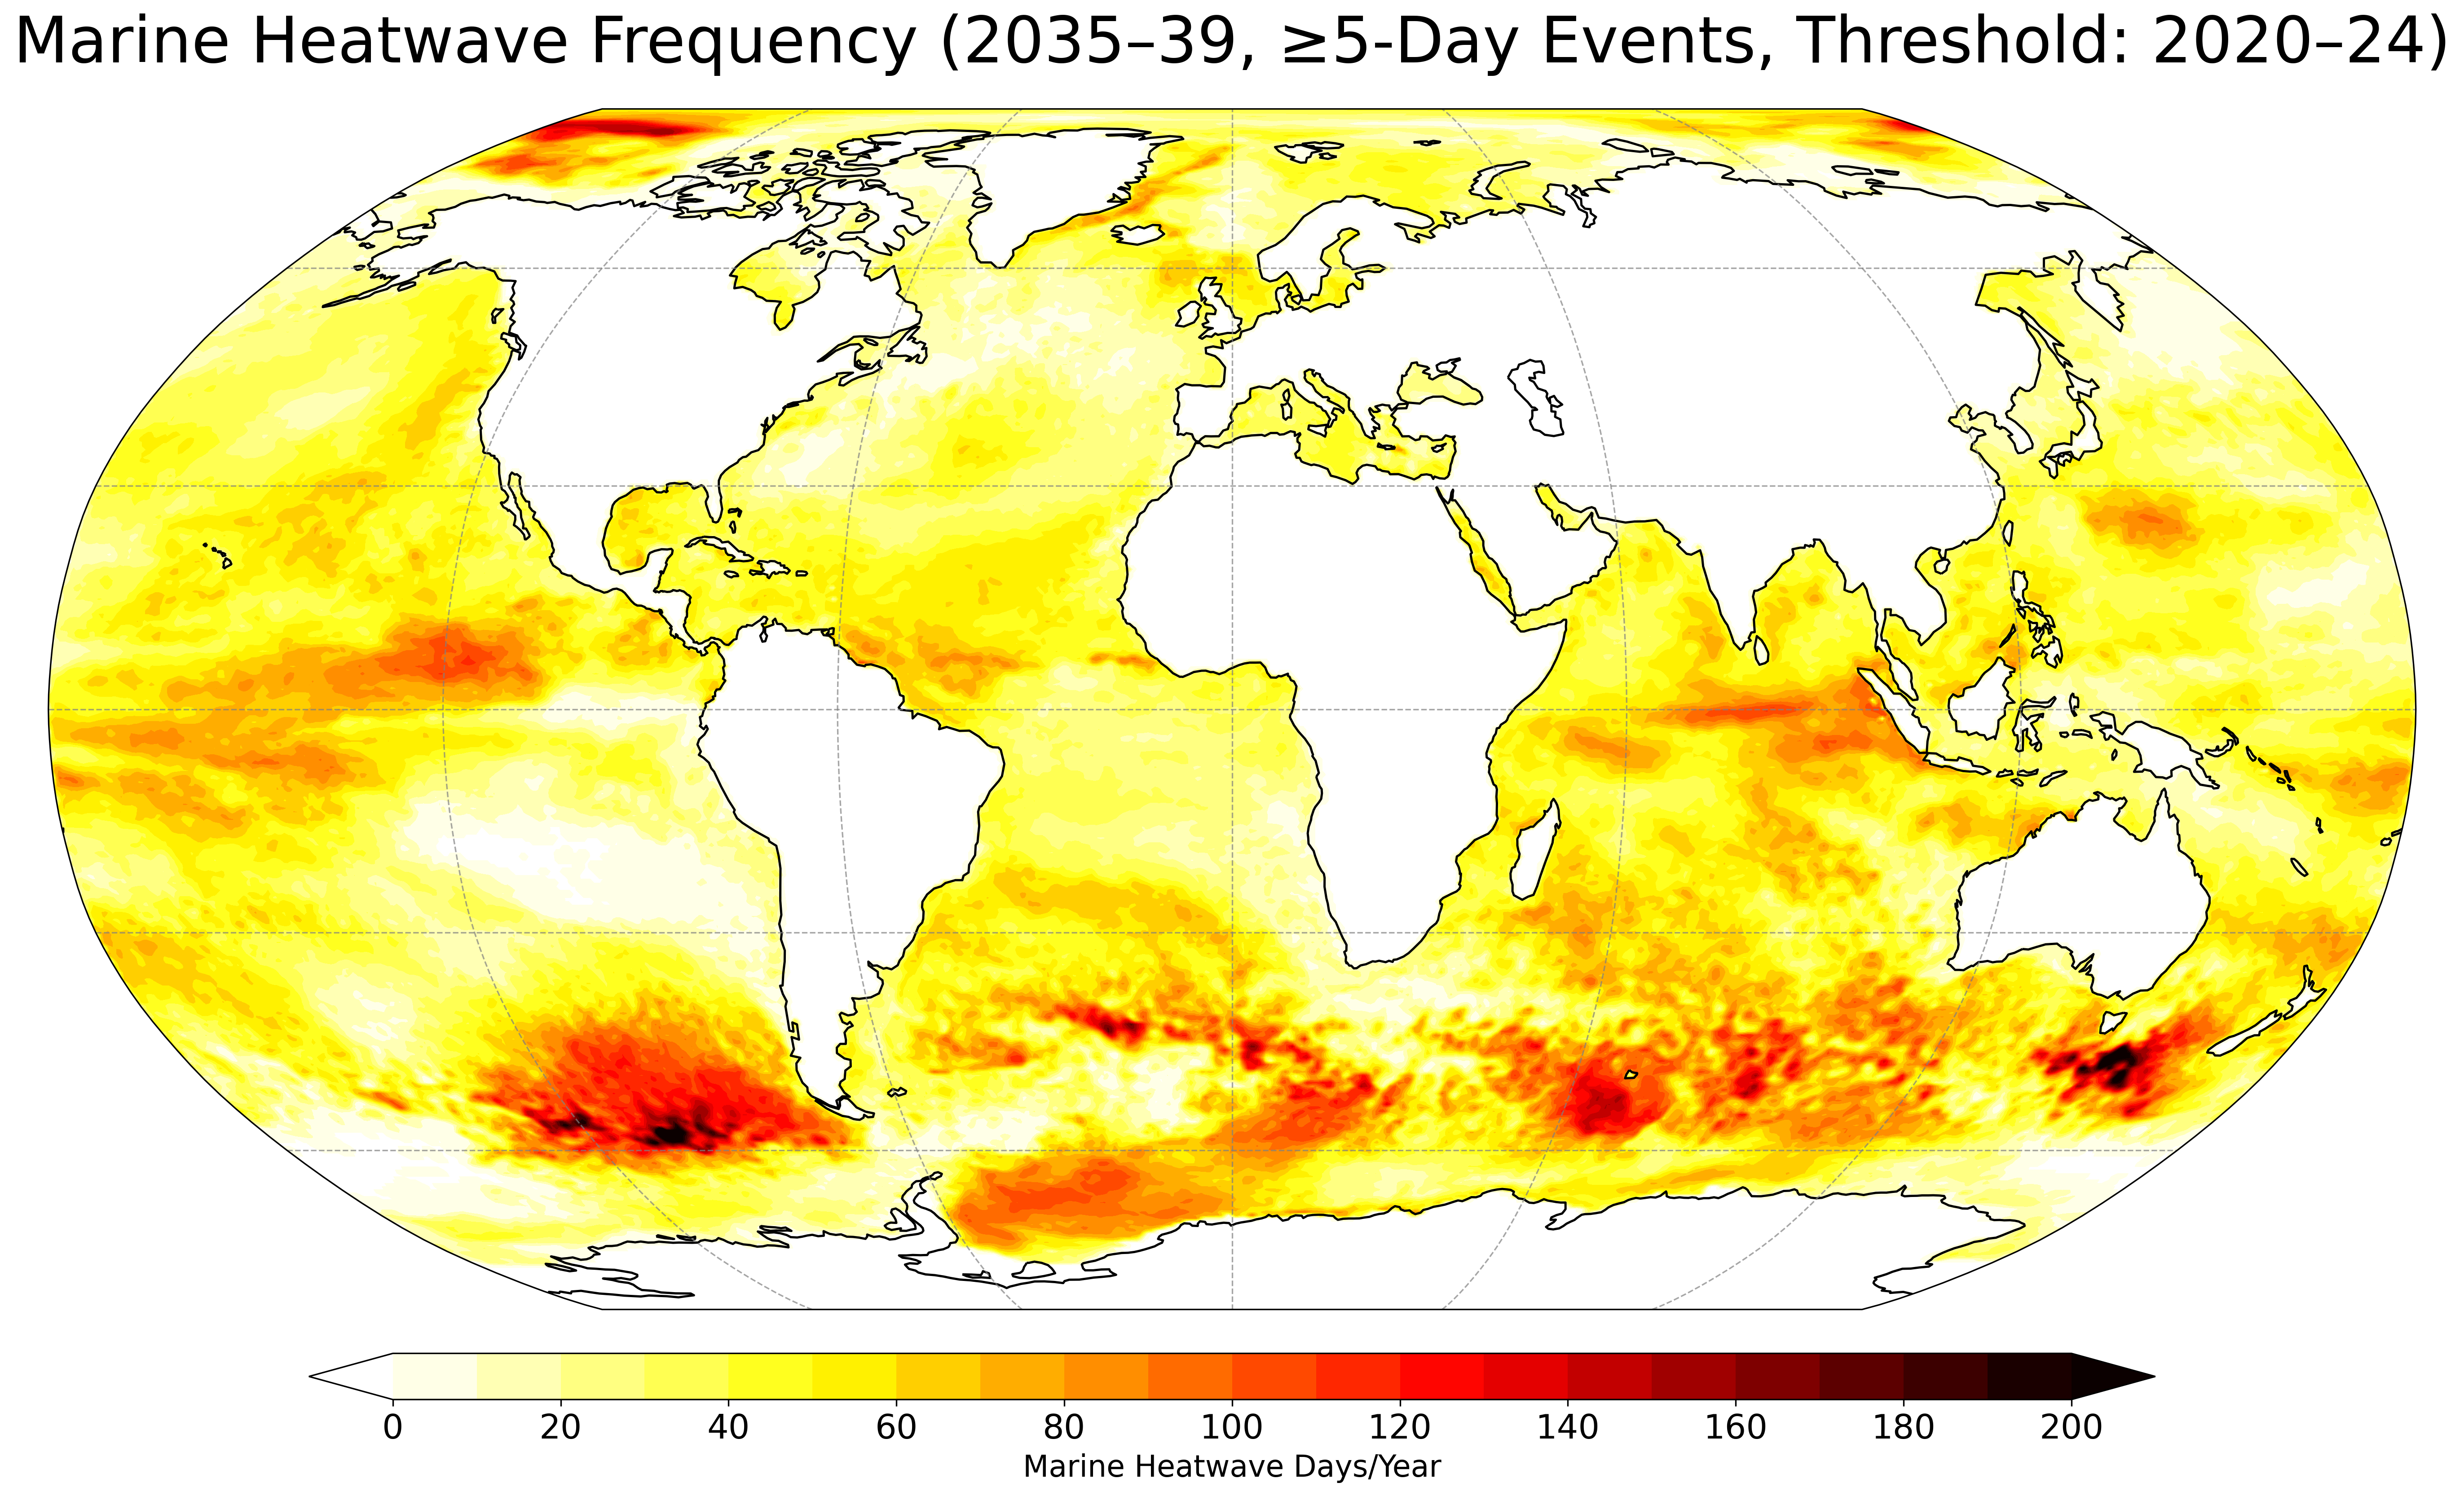

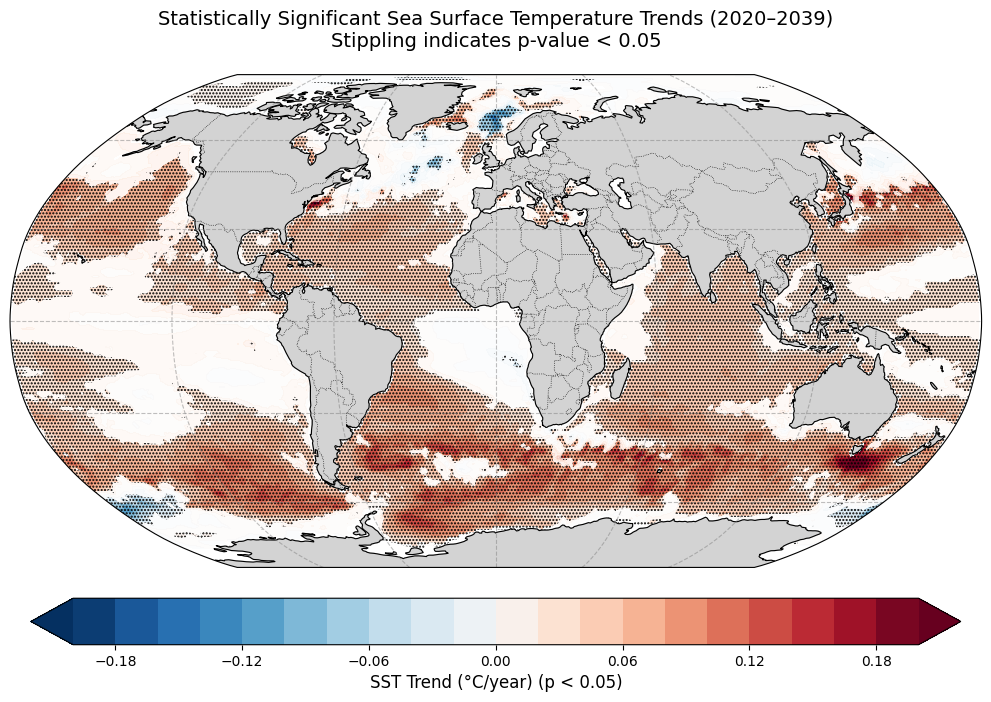

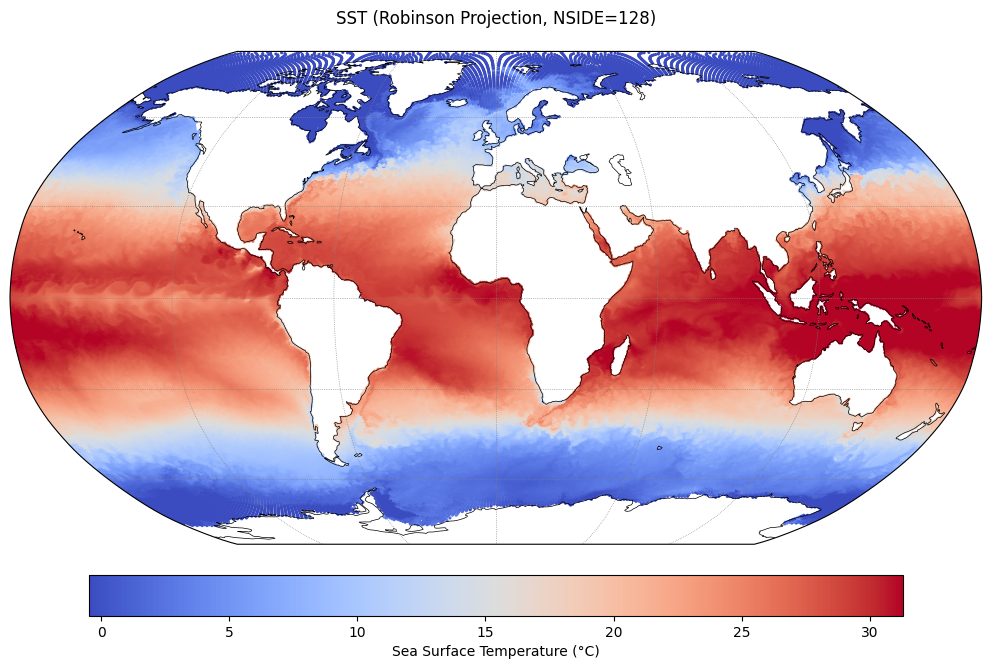

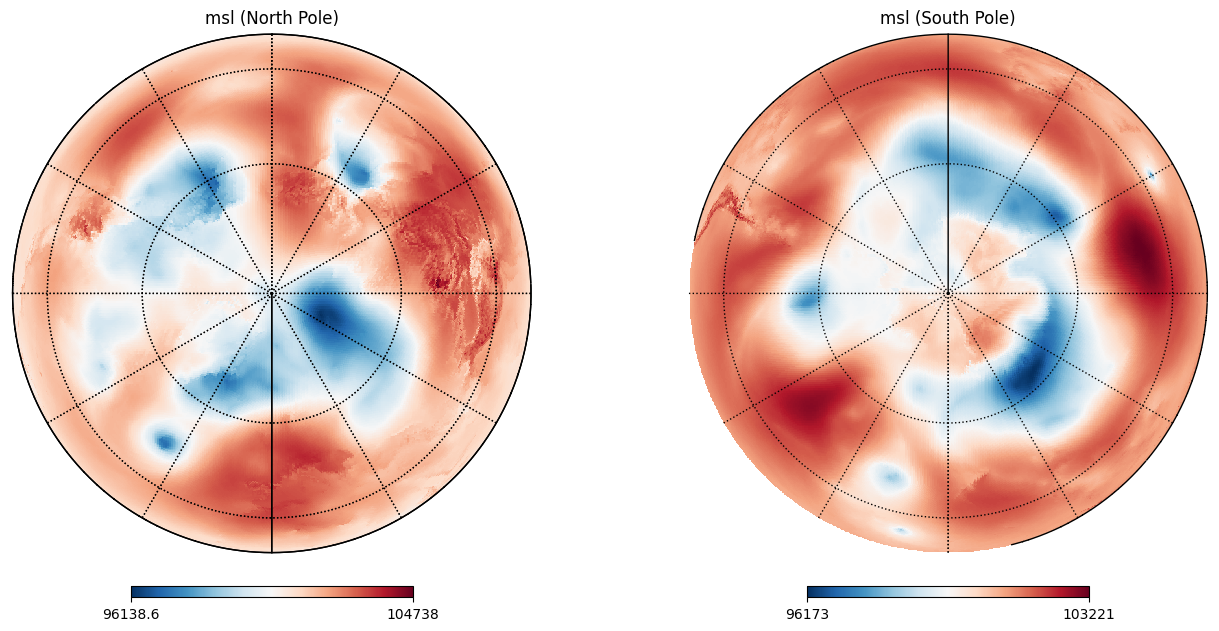

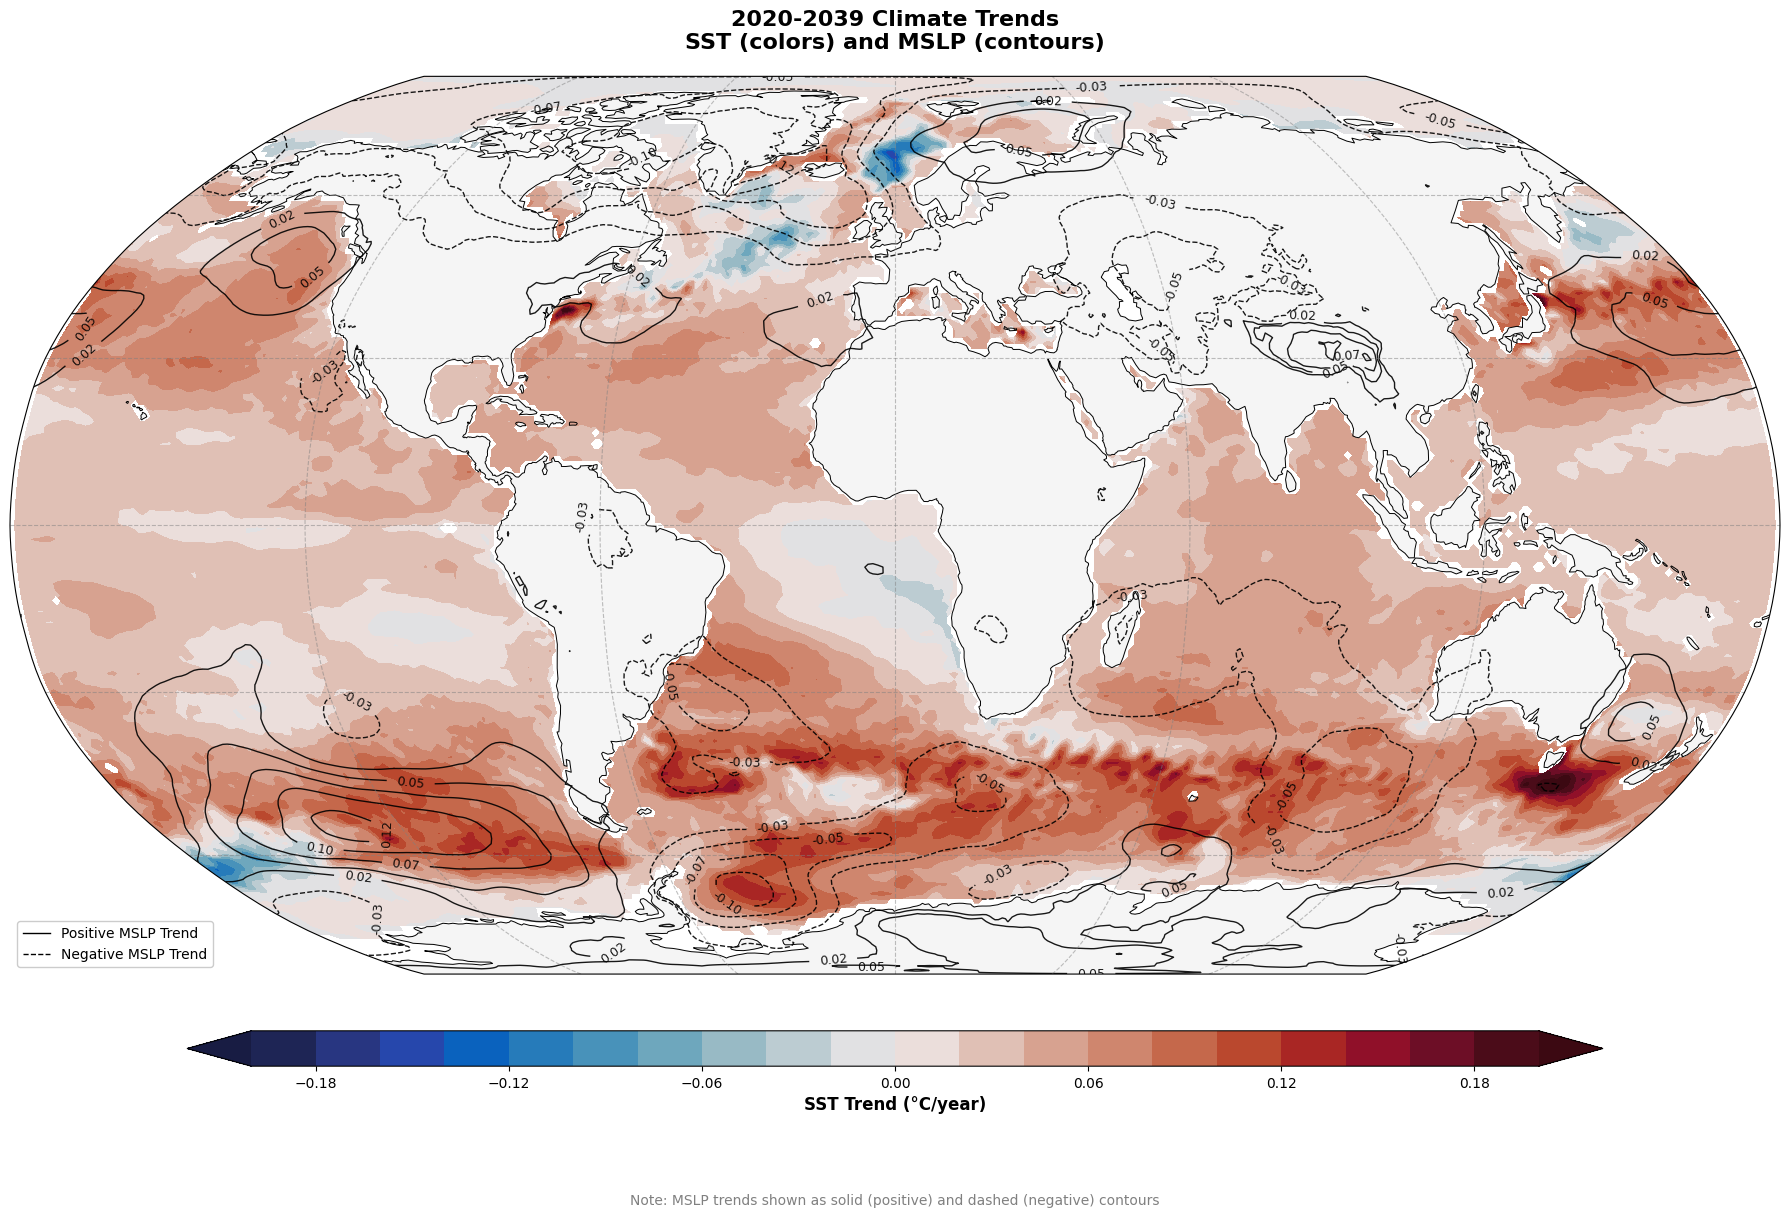

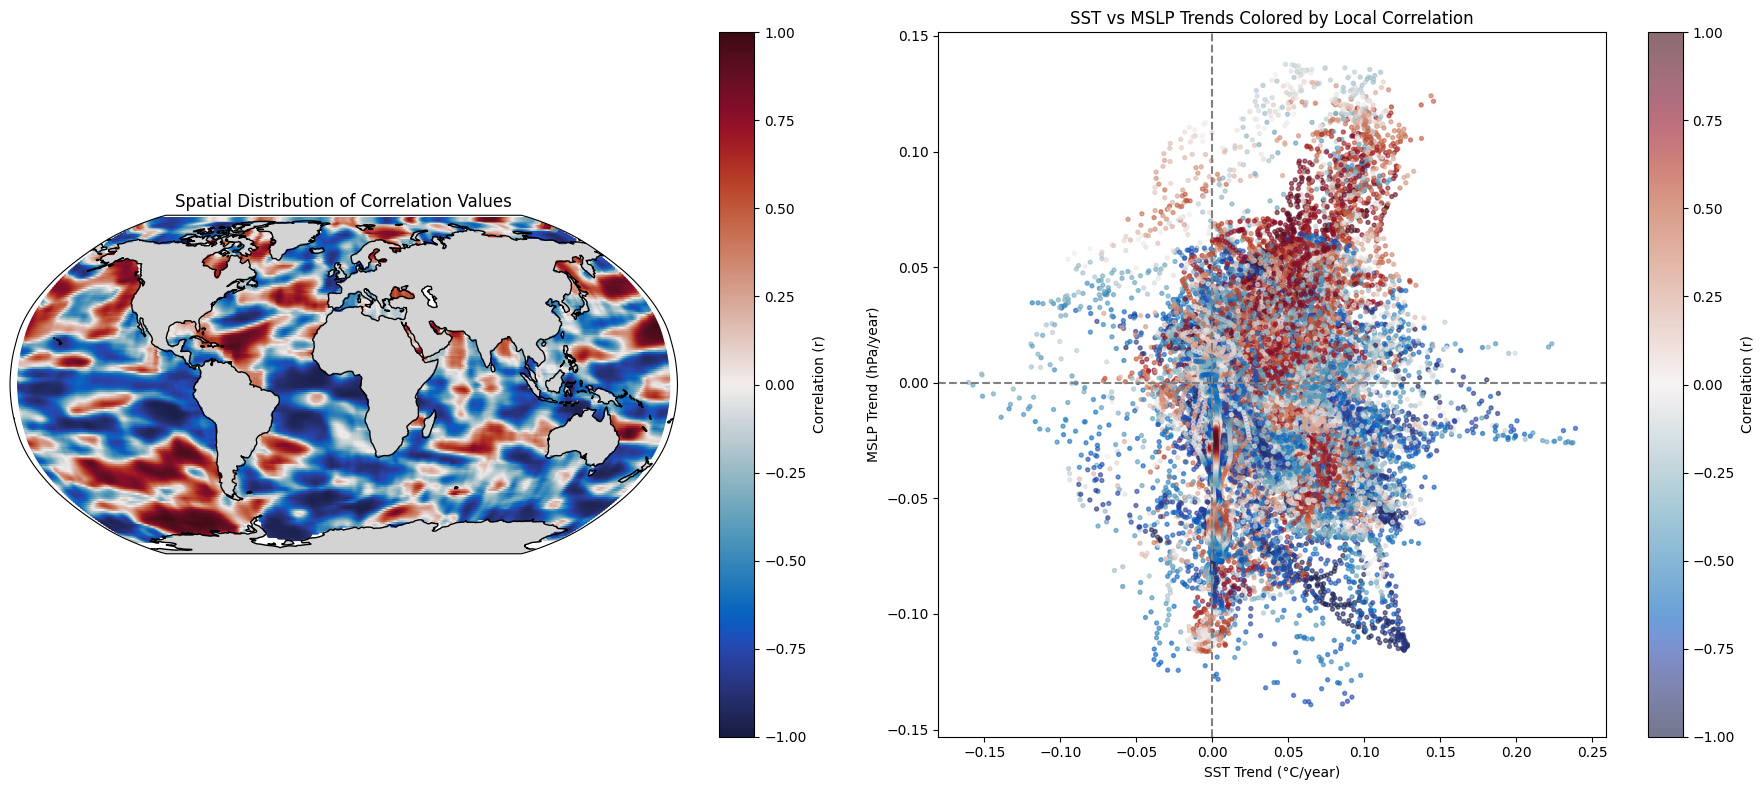

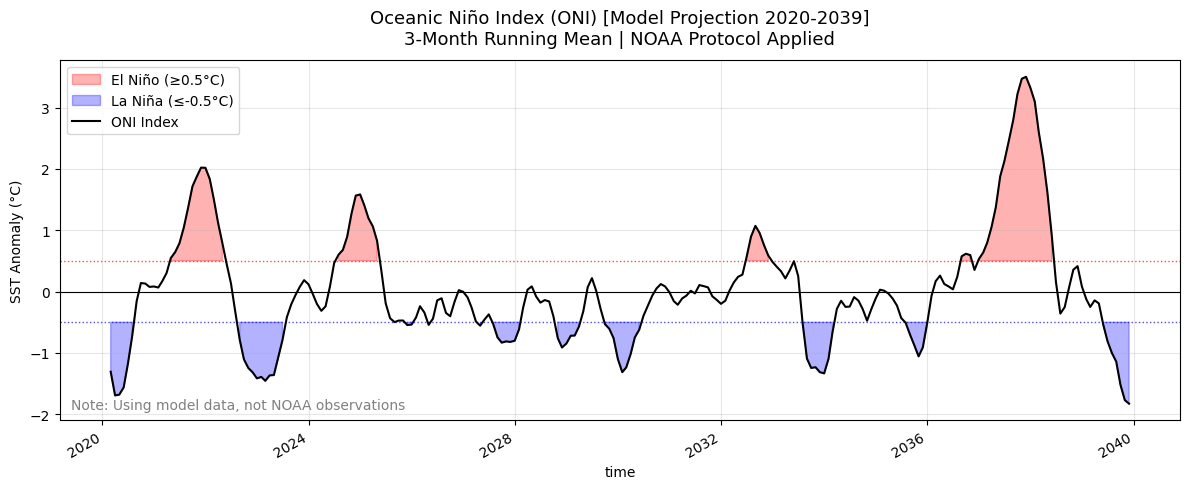